# Classical models

Every experiment with **classical (non-neural) machine-learning models** from the archived notebooks, run again on the base data and the common train / validation / test blocks, together with their conclusions.

The notebook brings together the model parts of `old_notebooks/` and runs them on `data/btc_hourly.csv.gz`, produced by `hourly-base-data.ipynb` (76,851 consecutive hours, 1 Jan 2018 → 8 Oct 2026). Nothing here reads the old `.npz` windows.

| Archived notebook | Author | What is taken |
|---|---|---|
| `models-and-hyperparameters-ver1.ipynb` (early draft) | Alberto | first model grid; everything in it was repeated by version 1 |
| `bitcoin-models-new-data.ipynb` (version 1) | Alberto | scale-free features, metrics, baselines, model grids, the three daily targets |
| `bitcoin-models-2018-2026.ipynb` (version 2) | Alberto | data from 2018, the three blocks, a single validation block, extended grids |
| `bitcoin-models-v3.ipynb` (version 3) | Alberto | long format, the hourly \|r\| target, prediction ranges, the metric mismatch, walk-forward CV, more models, ensembles, economic test, bootstrap |
| `v3-extensions.ipynb` | Filip | Binance / ETH attributes, monthly refits with recency weights, conformal ranges, the next-hour direction |
| `course-methods.ipynb` | Filip | the course-lab pipeline: regression, classification and SVMs on daily forecasts |

**Left out.** Neural networks (the scikit-learn `MLPRegressor` of the early draft and versions 1–2, the Keras MLP of `course-methods.ipynb`, the RNN/LSTM of `model_test.ipynb`) go in a separate notebook. The analysis of the data itself (autocorrelation, calendar patterns, K-Means regimes, other markets, macro variables) is in `data-analysis.ipynb`.

**Rules** (those of versions 2–3 and of `data-analysis.ipynb`)

- Three blocks by the date of the predicted hours: **train** Jan 2018 → Dec 2022, **validation** Jan 2023 → Jun 2024, **test** Jul 2024 → Oct 2026. A 192-hour purge before each border keeps every target hour in one block only.
- Every choice (hyperparameters, features, refit schedule, calibration) is made on train and validation only. The chosen model is refitted on train + validation and evaluated **once** on the test block.
- Some hourly experiments choose on the single validation block, as in version 2. The daily targets use walk-forward folds over train + validation, the method version 3 recommends (section 8.1 shows why).

**About the "What we see" texts and the conclusions.** They come from the archived notebooks, and each one names its source. Their numbers have been updated to the stored outputs of this run: a source label ending in "*numbers of this run*" keeps the archived wording, but its numbers (and, where the outputs no longer support it, its conclusion) are those of the cells above it. Quotes that cannot be checked here (plots only, experiments not rerun, version 1 with its other split, the start years before 2018) are kept as quotes and marked as archived or not rerun.

**Run time** ≈ 27 minutes (16 cores). The slowest parts are the monthly refits (section 6.5) and the long-format models (sections 4, 6 and 7).

**Structure**

1. Settings, data, features and blocks.
2. Metrics and baselines.
3. The assigned task: the 24 hourly returns (versions 1–2).
4. Hourly returns revisited: long format and the metric mismatch (version 3).
5. The direction of the next hour (`v3-extensions.ipynb`).
6. The size of each hourly move (version 3, `v3-extensions.ipynb`).
7. Hourly prediction ranges (version 3, `v3-extensions.ipynb`).
8. Next-day targets: return, direction and volatility (versions 1–3).
9. The course-lab pipeline (`course-methods.ipynb`).
10. What are the forecasts worth? An economic test (version 3).
11. How sure are we? Bootstrap confidence intervals (version 3).
12. Conclusions.

## 1. Settings, data, features and blocks

Run the notebook from the repo root, so `data/` and `utils/` are found. Features, targets, metrics and statistical tests come from `utils/hourly.py`; the Binance attributes from `utils/binance.py`.

In [1]:
import os
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, LogisticRegression, Ridge, SGDClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, log_loss,
                             make_scorer, mean_absolute_error, mean_squared_error, precision_score, r2_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, ParameterGrid, RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.multioutput import MultiOutputRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeRegressor

sys.path.insert(0, os.getcwd())   # utils/ is in the repo root
from utils import hourly as U
from utils.binance import load_binance, build_attributes

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA_PATH = os.path.join("data", "btc_hourly.csv.gz")
VAL_START = pd.Timestamp("2023-01-01")      # first predicted hour of the validation block
TEST_START = pd.Timestamp("2024-07-01")     # first predicted hour of the test block
WINDOW = pd.Timedelta(hours=192)            # purge before each border (168 input + 24 target hours, versions 2-3)
STRIDE = 6                                  # train and validation keep every 6th forecast origin
COST = 0.001                                # trading cost per unit of position changed (section 10)
RANDOM_STATE = 42
T_START = time.time()

# Colours and axes style shared by the plots (as in data-analysis.ipynb)
BLUE, ORANGE, AQUA, GREY, INK, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9", "#52514e", "#6250d6"


def tidy(ax, title=None):
    if title:
        ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

### 1.1 Data, forecast origins and targets

`Return` is converted to **percent** (0.4 = +0.4%), the unit of `utils/hourly.py`.

**Forecast origin.** Every hour with 30 days of history behind it and 24 hours after it is a forecast origin: the model sees the hours up to the origin and predicts the 24 hourly returns after it. `y_all[i, h]` is the return of hour *h* + 1 after origin *i*. This replaces the overlapping 168-hour windows of `data-preparation.ipynb`; version 3 rebuilt the continuous series from those windows, here it is read directly.

**Features** (version 3, section 2), computed at every hour of the series:

| Group | Features | Idea |
|---|---|---|
| **Base** (versions 1–2) | 42 features: last 24 returns, mean/std of returns over 24/72/168 h, 24 h and 7-day return, position in the week's range, distance to the week mean, High–Low range, volume vs. week, hour and weekday of the first predicted hour | all scale-free: they mean the same in 2018 and in 2026 |
| **B1: 30-day history** | log realized volatility of the last day, week and month (the *HAR* model), week vs. month volatility, 30-day return, distance to the 30-day mean, 30-day std of returns | volatility has a long memory |
| **B2: range-based volatility** | Parkinson and Garman–Klass volatility over 24 h, 1 week and 30 days | High, Low, Open and Close measure volatility more precisely than squared returns |

**Why scale-free features?** *(`bitcoin-models-new-data.ipynb`, decision a)* "Standardizing with one global mean and standard deviation does not remove the trend. [...] Tree models cannot predict outside the range they were trained on: every test window would look like 'the highest price ever seen'. Linear models would extrapolate the price level in a meaningless way." `data-analysis.ipynb` (section 2) measures it on the base data: 72% of the test hours trade above the highest train price.

In [2]:
hourly = pd.read_csv(DATA_PATH, index_col="Timestamp", parse_dates=True)
hourly["Return"] *= U.PCT
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "the hourly grid has holes"
ret, absr = hourly["Return"].values, hourly["Return"].abs().values

F_base, F_b1, F_b2 = U.base_features(hourly), U.long_lookback_features(hourly), U.range_vol_features(hourly)
FEAT = pd.concat([F_base, F_b1, F_b2], axis=1)
BASE, B1, B2 = list(F_base.columns), list(F_b1.columns), list(F_b2.columns)

# forecast origins: every hour with all features defined (30 days of history) and 24 hours after it
ok = np.isfinite(FEAT.values).all(axis=1)
first = int(np.argmax(ok))
assert ok[first:].all(), "missing feature values inside the series"
pos_all = np.arange(first, len(hourly) - U.H_AHEAD)
origins = hourly.index[pos_all]
y_all = np.stack([ret[pos_all + k] for k in range(1, U.H_AHEAD + 1)], axis=1)     # next 24 returns, %

print(f"{len(hourly):,} hours   {hourly.index[0]} -> {hourly.index[-1]}")
print(f"{len(origins):,} forecast origins   {origins[0]} -> {origins[-1]}")
print(f"features: base {len(BASE)}, B1 {len(B1)}, B2 {len(B2)}")

76,851 hours   2018-01-01 00:00:00 -> 2026-10-08 02:00:00
76,108 forecast origins   2018-01-30 23:00:00 -> 2026-10-07 02:00:00
features: base 42, B1 7, B2 6


### 1.2 The three blocks

As in versions 2–3: a block holds the origins whose 24 predicted hours fall inside it, and the origins of the earlier block whose last predicted hour is less than 192 hours before the border are dropped (purge). Train and validation keep every 6th origin (`STRIDE = 6`): consecutive origins share 23 of their 24 target hours, so this is ~6× faster and loses almost nothing (version 1, decision e). The test block keeps every origin.

The test origins start at 23:00 of 30 June 2024, so every 24th test origin is a forecast made at **23:00 for the next calendar day**: `test_days` are these **independent days**, used for the daily targets and for every significance test. (The archived notebooks used 00:00; `course-methods.ipynb` and `data-analysis.ipynb` use 23:00.) The features of validation and test origins look back into the previous block: that is not leakage, those hours are in the past at the moment of the forecast.

In [3]:
start_hour = origins + pd.Timedelta(hours=1)              # first predicted hour
day_end = origins + pd.Timedelta(hours=U.H_AHEAD)         # last predicted hour
blk = {
    "train": np.flatnonzero(day_end < VAL_START - WINDOW)[::STRIDE],
    "val": np.flatnonzero((start_hour >= VAL_START) & (day_end < TEST_START - WINDOW))[::STRIDE],
    "test": np.flatnonzero(start_hour >= TEST_START),
}
P = {k: pos_all[v] for k, v in blk.items()}               # positions in the hourly series
Y = {k: y_all[v] for k, v in blk.items()}                 # next 24 returns, %
D = {k: origins[v] for k, v in blk.items()}               # origin timestamps
n_tr, n_va = len(P["train"]), len(P["val"])
test_days = np.arange(0, len(P["test"]), 24)              # one origin per day (23:00) -> independent days
assert (D["test"][test_days].hour == 23).all()
ND = len(test_days)

display(pd.DataFrame({
    "origins": {k: len(P[k]) for k in P},
    "first origin": {k: D[k][0] for k in P},
    "last origin": {k: D[k][-1] for k in P},
    "avg |hourly move| %": {k: np.abs(Y[k]).mean() for k in P},
    "up days": {k: (U.compound(Y[k]) > 0).mean() for k in P},
}))
print(f"independent test days: {ND}")

,origins,first origin,last origin,avg |hourly move| %,up days
train,7149,2018-01-30 23:00:00,2022-12-22 23:00:00,0.484986,0.514897
val,2153,2022-12-31 23:00:00,2024-06-21 23:00:00,0.301283,0.530887
test,19876,2024-06-30 23:00:00,2026-10-07 02:00:00,0.319275,0.517408


independent test days: 829


### 1.3 Wide and long format

- **Wide** (versions 1–2): one row per origin with its features; the target is the 24 returns (or one daily value).
- **Long** (version 3, A6): every origin becomes 24 rows, one per predicted hour, with extra columns saying *which* hour is predicted. One model then learns what is common to all hours and what is specific to some. Section 4 explains it in detail.

| Per-hour column | Meaning |
|---|---|
| `h_ahead` | 1 … 24: how many hours after the origin |
| `tgt_hour_sin/cos`, `tgt_dow_sin/cos` | hour of day and weekday of the **predicted** hour |
| **B3:** `tgt_weekend` | 1 if the predicted hour is on Saturday/Sunday |
| **B3:** `tgt_hour_profile` | average size of moves at that hour of day in the train block, divided by the overall average |
| **B3:** `absret_same_hour_1d`, `absret_same_hour_7d` | size of the move at the same hour yesterday and one week ago |
| **B3:** `ret_same_hour_1d` | return at the same hour yesterday (the lag-24 reversal of `data-analysis.ipynb`, section 4) |

`rule_abs` is the strongest simple rule for the size of a move: **last week's average |r| × the hour-of-day profile** (version 3, section 5).

In [4]:
H_BASE = ["h_ahead", "tgt_hour_sin", "tgt_hour_cos", "tgt_dow_sin", "tgt_dow_cos"]
B3 = ["tgt_weekend", "tgt_hour_profile", "absret_same_hour_1d", "absret_same_hour_7d", "ret_same_hour_1d"]
tr_abs = hourly["Return"].abs().loc[D["train"][0]: D["train"][-1] + pd.Timedelta(hours=U.H_AHEAD)]
HOUR_PROFILE = (tr_abs.groupby(tr_abs.index.hour).mean() / tr_abs.mean()).values
week_abs = pd.Series(absr).rolling(168).mean().values               # last week's average |r| at each hour


def Xw(block, cols):
    # Wide format: one row per origin
    return FEAT[cols].values[P[block]]


def Xl(block, cols, hcols=H_BASE):
    # Long format: 24 rows per origin (origin-major order); cols = origin features, hcols = per-hour features
    p = P[block]
    base = np.repeat(FEAT[cols].values[p], 24, axis=0)
    h_ = np.tile(np.arange(1, 25), len(p))
    tp = np.repeat(p, 24) + h_                                       # position of the predicted hour
    t = hourly.index[tp]
    extra = {
        "h_ahead": h_,
        "tgt_hour_sin": np.sin(2 * np.pi * t.hour / 24), "tgt_hour_cos": np.cos(2 * np.pi * t.hour / 24),
        "tgt_dow_sin": np.sin(2 * np.pi * t.dayofweek / 7), "tgt_dow_cos": np.cos(2 * np.pi * t.dayofweek / 7),
        "tgt_weekend": (t.dayofweek >= 5).astype(float),
        "tgt_hour_profile": HOUR_PROFILE[t.hour],
        "absret_same_hour_1d": absr[tp - 24], "absret_same_hour_7d": absr[tp - 168],
        "ret_same_hour_1d": ret[tp - 24],
    }
    return np.hstack([base, np.column_stack([extra[c] for c in hcols])])


def yl(block, kind="abs"):
    v = Y[block].reshape(-1)
    return np.abs(v) if kind == "abs" else v


def rule_abs(block):
    # Baseline: last week's average |r| x hour-of-day profile of the predicted hour
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return week_abs[p] * HOUR_PROFILE[hourly.index[p + h_].hour]

### 1.4 Shared helpers

- `metrics()`: the return metrics of versions 1–2 (section 2).
- `tune()`: fits each setting of a grid on one sample and scores it on another (the single validation block, as in version 2).
- `cv_tune()`: the same with **walk-forward folds** over train + validation (version 3, C1): 4 folds with a gap of 32 origins (= 192 hours) before each validation fold. In the long format the folds are made of origins, so the 24 rows of one forecast never end up on both sides.
- `SUMMARY` collects the main test result of each section for the conclusions.

In [5]:
def safe_corr(a, b):
    return U.safe_corr(a, b)


def metrics(y_true, y_pred):
    # Return metrics of versions 1-2, on returns in %
    nz = y_true != 0
    mae, mae0 = mean_absolute_error(y_true, y_pred), np.abs(y_true).mean()
    d_true, d_pred = U.compound(y_true), U.compound(y_pred)
    return {"MAE": mae, "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE_skill": 1 - mae / mae0,
            "R2_oos": U.r2_oos(y_true, y_pred), "IC": safe_corr(y_pred, y_true),
            "HourDirAcc": ((y_pred[nz] > 0) == (y_true[nz] > 0)).mean(),
            "DayDirAcc": ((d_pred > 0) == (d_true > 0)).mean()}


INT_KEYS = ("max_depth", "min_samples_leaf", "max_iter", "n_neighbors", "n_estimators")


def as_int(p):
    return {k: (int(v) if k in INT_KEYS and v is not None and not pd.isna(v) else
                None if k == "max_depth" and pd.isna(v) else
                v.item() if isinstance(v, np.generic) else v) for k, v in p.items()}


def tune(make_model, grid, Xa, ya, Xb, yb, score_fn, show=True):
    # Fit each setting on (Xa, ya), score on (Xb, yb). score_fn(y, pred) -> dict with key 'score'
    rows, grid = [], list(ParameterGrid(grid))
    for p in grid:
        t0 = time.time()
        s = score_fn(yb, make_model(**p).fit(Xa, ya).predict(Xb))
        rows.append({**p, **s, "seconds": round(time.time() - t0, 1)})
    t = pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)
    if show:
        display(t.round(4))
    return t, as_int(t.iloc[0][list(grid[0])].to_dict())


WF = list(TimeSeriesSplit(n_splits=4, gap=int(np.ceil(WINDOW / pd.Timedelta(hours=1) / STRIDE))).split(np.arange(n_tr + n_va)))
SINGLE = [(np.arange(n_tr), np.arange(n_tr, n_tr + n_va))]
tv_dates = D["train"].append(D["val"])
for k, (a, b) in enumerate(WF, 1):
    print(f"walk-forward fold {k}: train {tv_dates[a[0]].date()} -> {tv_dates[a[-1]].date()} ({len(a)})  |  "
          f"validate {tv_dates[b[0]].date()} -> {tv_dates[b[-1]].date()} ({len(b)})")


def rows24(idx):
    return (np.asarray(idx)[:, None] * 24 + np.arange(24)).ravel()


def cv_tune(make_model, grid, X, y, folds, score_fn, long=False, show=True):
    # Average score over folds (each fold: fit on its train part, score on its validation part)
    out, grid = [], list(ParameterGrid(grid))
    for p in grid:
        t0, sc = time.time(), []
        for a, b in folds:
            a, b = (rows24(a), rows24(b)) if long else (a, b)
            sc.append(score_fn(y[b], make_model(**p).fit(X[a], y[a]).predict(X[b]))["score"])
        out.append({**p, "score": np.mean(sc), "score_std": np.std(sc, ddof=1) if len(sc) > 1 else np.nan,
                    **{f"fold{i + 1}": s for i, s in enumerate(sc)}, "seconds": round(time.time() - t0, 1)})
    t = pd.DataFrame(out).sort_values("score", ascending=False).reset_index(drop=True)
    if show:
        display(t.round(4))
    return t, as_int(t.iloc[0][list(grid[0])].to_dict()) if grid[0] else {}


r2s = lambda y, p: {"score": U.r2(y, p)}
r2o = lambda y, p: {"score": U.r2_oos(y, p)}
vol_scores = lambda y, p: {"score": U.r2(y, p), "MAE": mean_absolute_error(y, p), "corr": safe_corr(p, y)}
ret_scores = lambda y, p: {"score": U.r2_oos(y, p), "MAE_skill": 1 - np.abs(y - p).mean() / np.abs(y).mean(),
                           "IC": safe_corr(p, y)}
make_ridge = lambda alpha: make_pipeline(StandardScaler(), Ridge(alpha=alpha))
make_gb = lambda **p: HistGradientBoostingRegressor(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
SUMMARY = []

walk-forward fold 1: train 2018-01-30 -> 2019-05-03 (1830)  |  validate 2019-05-11 -> 2020-08-18 (1860)
walk-forward fold 2: train 2018-01-30 -> 2020-08-10 (3690)  |  validate 2020-08-18 -> 2021-11-26 (1860)
walk-forward fold 3: train 2018-01-30 -> 2021-11-18 (5550)  |  validate 2021-11-26 -> 2023-03-14 (1860)
walk-forward fold 4: train 2018-01-30 -> 2023-03-06 (7410)  |  validate 2023-03-15 -> 2024-06-21 (1860)


## 2. Metrics and baselines

*Texts from `bitcoin-models-new-data.ipynb` (version 1), sections 4 and 6.*

All values are computed on returns in **percent**. "Zero forecast" means predicting 0% change for every hour.

| Metric | What it measures | Better | No-skill value |
|---|---|---|---|
| **MAE** | Average absolute error per predicted hour, in %. "On average we miss by x%." | lower | ≈ the average size of an hourly move (zero forecast) |
| **RMSE** | Square root of the average squared error, in %. Punishes big misses more than MAE. | lower | ≈ the standard deviation of hourly returns |
| **MAE skill** | `1 − MAE_model / MAE_zero`. Share of the zero forecast's error that the model removes. Makes periods with different volatility comparable. | higher | **0** = as good as predicting zero |
| **R²_oos** | `1 − SSE_model / SSE_zero`: the same idea with squared errors, the usual "out-of-sample R²" in finance. It compares against the zero forecast instead of the test mean (which the model could not know in advance). | higher | **0** |
| **IC** (information coefficient) | Correlation between predicted and actual returns. Measures whether the model ranks hours correctly, even if the size of its predictions is wrong. | higher | **0**; 0.02–0.05 is considered useful in finance |
| **Hourly / daily direction accuracy** | Share of hours (or of days, after compounding the 24 forecasts) whose sign is right. | higher | **≈ 50%** |
| **p-value (daily direction)** | Binomial test of the daily accuracy against 50%, on independent days only. | lower | above 0.05: cannot be told apart from a coin flip |
| **Balanced accuracy** | Average of the accuracy on up days and on down days. | higher | **0.50** for any rule that always says the same thing |

"**A trap with direction accuracy.** About 53% of the test days were up days (Bitcoin rose over the period). A model that simply always says 'up' therefore gets ≈53% accuracy, and the binomial test even calls it 'significant', although it knows nothing about individual days. This is why we also report **balanced accuracy**, which 'always up' cannot fool (it scores exactly 0.50), and why every model must be compared with the 'mean per hour' baseline, which behaves like 'always up'." *(In the test block of this run only 50.1% of the independent test days were up days, section 8.3, so 'always up' gets ≈50% here; the trap returns in any trending period.)*

"**Why several metrics?** MAE and RMSE answer 'how far off are the numbers?'. For returns the honest answer is 'about as far off as predicting zero', because hourly moves are mostly noise. IC and direction accuracy answer a different question, 'does the model know which way things go?', which can be slightly positive even when MAE does not improve."

The other targets bring their own metrics (R² for volatility, pinball loss and coverage for ranges, ROC AUC and log loss for classification); they are explained in their sections.

**Baselines** (no learning). "A model is only interesting if it beats simple rules that need no learning":

- **Zero**: 0% change for every hour. For a random walk this is the best possible forecast, which is why it is the reference for MAE skill and R²_oos. (For direction it counts as always "not up".)
- **Mean per hour**: the average return of each of the 24 future hours over train + validation. Since Bitcoin went up over time this is slightly positive, so for direction it means "always up".
- **Persistence**: tomorrow's 24 hours repeat the last 24 hours.
- **Reversal of the last hour**: only the first hour is forecast, as −0.05 × the last observed return, a small bet on mean reversion.

## 3. The assigned task: the 24 hourly returns (versions 1–2)

*Section and texts from `bitcoin-models-2018-2026.ipynb` (version 2), sections 5–9; the model descriptions from version 1.*

Wide format, the 42 base features, one model for the 24 hourly returns.

**Validation method** (version 2)
- *A fixed validation block for choosing hyperparameters.* Each setting is trained on the train block and scored on the validation block. The setting with the best **validation MAE skill** wins.
- *The price of a single block.* "One period can be unusual (2023 was a calm year, early 2024 a strong rally). To see how stable a result is, the validation block is cut into **3 consecutive half-years**. The skill is computed on each part, and `val_skill_std` reports their standard deviation. A difference between two settings smaller than this value is not meaningful."
- *The test block, used once per model.* The chosen setting is refitted on train + validation and evaluated once on every test origin.
- *A significance check for direction.* One origin per day (the independent `test_days`) and a binomial test against 50%, plus balanced accuracy.

**How to read the tuning tables** (version 1)
- "`train_skill` clearly above 0 while `val_skill` is below 0 means **overfitting**: the model learned patterns of the training period that do not repeat."
- "Both close to 0 means the model is (correctly) cautious and stays near the zero forecast."
- "**General rule:** if the best value sits at the edge of the grid, extend the grid in that direction and run again." The grids below are the extended grids of version 2.

Version 1 used walk-forward folds inside its training period instead of one block; the numbers of both versions are compared in the conclusions.

In [6]:
Ftr, Fva, Fte = Xw("train", BASE), Xw("val", BASE), Xw("test", BASE)
Ytr, Yva, Yte = Y["train"], Y["val"], Y["test"]
Ftv, Ytv = np.vstack([Ftr, Fva]), np.vstack([Ytr, Yva])
VAL_PARTS = np.array_split(np.arange(n_va), 3)                 # 3 consecutive half-years of the validation block
last24_te = ret[P["test"][:, None] + np.arange(-23, 1)]        # the last 24 observed returns at each test origin
results, test_preds = [], {}


def val_tune(make_model, grid):
    # Train on the train block, score on the validation block: one row per setting, best first
    rows = []
    for params in ParameterGrid(grid):
        t0 = time.time()
        m = make_model(**params).fit(Ftr, Ytr)
        pred_va = m.predict(Fva)
        va = metrics(Yva, pred_va)
        parts = [metrics(Yva[p], pred_va[p])["MAE_skill"] for p in VAL_PARTS]
        rows.append({**params, "train_skill": metrics(Ytr, m.predict(Ftr))["MAE_skill"],
                     "val_skill": va["MAE_skill"], "val_skill_std": np.std(parts, ddof=1),
                     "val_MAE": va["MAE"], "val_IC": va["IC"], "val_DayDirAcc": va["DayDirAcc"],
                     "seconds": round(time.time() - t0, 1)})
    out = pd.DataFrame(rows).sort_values("val_skill", ascending=False).reset_index(drop=True)
    display(out.round(4))
    return out


def best_params(table, keys):
    return as_int(table.loc[0, keys].to_dict())


def final_report(name, model=None, pred=None):
    # Refit on train + validation, evaluate once on the test block
    if pred is None:
        pred = model.fit(Ftv, Ytv).predict(Fte)
    m = metrics(Yte, pred)
    d_true, d_pred = U.compound(Yte[test_days]) > 0, U.compound(pred[test_days]) > 0
    hits = d_true == d_pred
    m["DayDirAcc_indep"] = hits.mean()
    m["DayBalAcc_indep"] = balanced_accuracy_score(d_true, d_pred)
    m["p_value"] = stats.binomtest(int(hits.sum()), len(hits), 0.5, alternative="greater").pvalue
    results.append({"Model": name, **m})
    test_preds[name] = pred
    print(f"{name:<40} MAE={m['MAE']:.4f}  skill={m['MAE_skill']:+.4f}  R2oos={m['R2_oos']:+.4f}  IC={m['IC']:+.3f}  "
          f"DayDir={m['DayDirAcc_indep']:.3f} (p={m['p_value']:.2f})  DayBalAcc={m['DayBalAcc_indep']:.3f}")
    return model


final_report("Baseline: zero", pred=np.zeros_like(Yte))
final_report("Baseline: mean per hour", pred=np.tile(Ytv.mean(0), (len(Yte), 1)))
final_report("Baseline: persistence", pred=last24_te)
rev = np.zeros_like(Yte)
rev[:, 0] = -0.05 * ret[P["test"]]
final_report("Baseline: last-hour reversal", pred=rev);

Baseline: zero                           MAE=0.3193  skill=-0.0000  R2oos=+0.0000  IC=+nan  DayDir=0.499 (p=0.53)  DayBalAcc=0.500
Baseline: mean per hour                  MAE=0.3194  skill=-0.0004  R2oos=-0.0004  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


Baseline: persistence                    MAE=0.4736  skill=-0.4834  R2oos=-1.0185  IC=-0.009  DayDir=0.497 (p=0.58)  DayBalAcc=0.497


Baseline: last-hour reversal             MAE=0.3192  skill=+0.0001  R2oos=-0.0001  IC=+0.002  DayDir=0.501 (p=0.50)  DayBalAcc=0.501


### 3.1 Ridge and Lasso

"Linear regression with an L2 penalty on the coefficients. One model predicts all 24 hours. Features are standardized inside the pipeline." Lasso uses an L1 penalty, which sets some coefficients exactly to 0: "It doubles as **feature selection** [...]. If it removes everything, that tells you it found nothing better than the average."

| Hyperparameter | Effect | Grid |
|---|---|---|
| Ridge `alpha` | Small: the model follows the training data closely (overfits). Large: coefficients shrink to 0 and the model becomes the "mean per hour" baseline. | 0.1 → 10⁹ (log scale) |
| Lasso `alpha` | larger means fewer features kept | 0.003 → 1 |

In [7]:
ridge_cv = val_tune(make_ridge, {"alpha": [0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]})
p_ridge = best_params(ridge_cv, ["alpha"])
final_report(f"Ridge {p_ridge}", make_ridge(**p_ridge))

make_lasso = lambda alpha: make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=5000))
lasso_cv = val_tune(make_lasso, {"alpha": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]})
p_lasso = best_params(lasso_cv, ["alpha"])
lasso_model = final_report(f"Lasso {p_lasso}", make_lasso(**p_lasso))
kept = pd.DataFrame(lasso_model[-1].coef_.T, index=BASE).abs().sum(axis=1)
print(f"Lasso keeps {(kept > 0).sum()} of {len(kept)} features (non-zero for at least one hour)"
      + (f": {list(kept[kept > 0].sort_values(ascending=False).head(8).index)}" if (kept > 0).any() else "."))

,alpha,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,1.000000e+06,0.0001,-0.0007,0.0005,0.3015,-0.0182,0.5309,0.0
1,1.000000e+05,0.0009,-0.0007,0.0005,0.3015,-0.0094,0.5323,0.0
2,1.000000e+07,-0.0000,-0.0007,0.0005,0.3015,-0.0190,0.5309,0.0
3,1.000000e+08,-0.0000,-0.0007,0.0005,0.3015,-0.0191,0.5309,0.0
4,1.000000e+09,-0.0000,-0.0007,0.0005,0.3015,-0.0191,0.5309,0.0
5,1.000000e+04,0.0026,-0.0042,0.0012,0.3026,0.0095,0.5114,0.0
6,1.000000e+03,0.0002,-0.0141,0.0006,0.3055,0.0138,0.5026,0.0
7,1.000000e+02,-0.0016,-0.0187,0.0011,0.3069,0.0136,0.5007,0.0
8,1.000000e+01,-0.0020,-0.0198,0.0016,0.3073,0.0136,0.4998,0.0
9,1.000000e+00,-0.0025,-0.0204,0.0020,0.3074,0.0139,0.4961,0.0


Ridge {'alpha': 1000000.0}               MAE=0.3194  skill=-0.0003  R2oos=-0.0003  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


,alpha,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,0.300,-0.0000,-0.0007,0.0005,0.3015,-0.0191,0.5309,0.0
1,0.100,-0.0000,-0.0007,0.0005,0.3015,-0.0191,0.5309,0.0
2,1.000,-0.0000,-0.0007,0.0005,0.3015,-0.0191,0.5309,0.0
3,0.030,0.0011,-0.0017,0.0006,0.3018,-0.0077,0.5365,0.1
4,0.010,0.0016,-0.0075,0.0014,0.3035,0.0094,0.5151,0.1
5,0.003,-0.0000,-0.0143,0.0004,0.3056,0.0132,0.5049,0.2


Lasso {'alpha': 0.3}                     MAE=0.3194  skill=-0.0004  R2oos=-0.0004  IC=+0.000  DayDir=0.501 (p=0.50)  DayBalAcc=0.500
Lasso keeps 0 of 42 features (non-zero for at least one hour).


### 3.2 k-Nearest Neighbors

"Finds the *k* past weeks most similar to the current one and averages what happened the day after: 'history rhymes'. It has no real training phase, so it is very easy to explain. Scaling matters because it is distance-based." With `weights="distance"` the train skill is ≈ 1 (every training point is its own nearest neighbour), so only the validation score is meaningful there.

| Hyperparameter | Effect | Grid |
|---|---|---|
| `n_neighbors` | Few neighbours: noisy forecasts. Many: smooth, close to the average. | 10 → 6000 |
| `weights` | `uniform` or `distance` | both |

In [8]:
make_knn = lambda n_neighbors, weights: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=n_neighbors, weights=weights))
knn_cv = val_tune(make_knn, {"n_neighbors": [10, 50, 200, 500, 1000, 2000, 4000, 6000], "weights": ["uniform", "distance"]})
p_knn = best_params(knn_cv, ["n_neighbors", "weights"])
final_report(f"KNN {p_knn}", make_knn(**p_knn));

,n_neighbors,weights,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,2000,distance,1.0000,-0.0001,0.0005,0.3013,-0.0013,0.4863,4.3
1,4000,distance,1.0000,-0.0002,0.0002,0.3013,-0.0037,0.5086,7.9
2,2000,uniform,0.0007,-0.0002,0.0005,0.3013,-0.0012,0.4821,2.8
3,4000,uniform,0.0004,-0.0003,0.0001,0.3014,-0.0042,0.5095,4.7
4,6000,distance,1.0000,-0.0004,0.0002,0.3014,-0.0131,0.5309,12.4
5,1000,distance,1.0000,-0.0005,0.0011,0.3014,-0.0051,0.4914,2.5
6,1000,uniform,0.0011,-0.0005,0.0011,0.3014,-0.0054,0.4858,1.7
7,6000,uniform,0.0001,-0.0006,0.0002,0.3015,-0.0151,0.5309,6.3
8,500,uniform,0.0015,-0.0014,0.0010,0.3017,-0.0003,0.4807,1.1
9,500,distance,1.0000,-0.0015,0.0010,0.3017,-0.0004,0.4844,1.5


KNN {'n_neighbors': 2000, 'weights': 'distance'} MAE=0.3194  skill=-0.0005  R2oos=-0.0003  IC=+0.003  DayDir=0.510 (p=0.29)  DayBalAcc=0.510


### 3.3 Random Forest and Gradient Boosting

"An average of many decision trees, each trained on a random sample of the data and of the features. It captures non-linear effects (for example 'after a big drop in a calm week…') and predicts the 24 hours together. No scaling needed."

Gradient Boosting: "Trees are built one after another, each correcting the errors of the previous ones. It is usually the strongest classical model on tabular data. It predicts one target at a time, so `MultiOutputRegressor` trains 24 models (one per hour) [...]. `loss="absolute_error"` makes it optimise MAE directly, which is robust to extreme hours."

| Model | Hyperparameter | Effect | Grid |
|---|---|---|---|
| RF | `max_depth` | the main overfitting control | 2, 4, 8, 16 |
| RF | `min_samples_leaf` | larger: smoother, more cautious forecasts | 20, 100, 300 |
| RF | `max_features` | share of features at each split | 0.3, 0.6 |
| RF | `n_estimators` | more trees: more stable, never more overfitting | 50 to tune, 300 for the final model |
| GB | `learning_rate` | smaller: more cautious | 0.01, 0.03, 0.1 |
| GB | `max_depth` | 1 = a single split per tree | 1, 2, 4 |
| GB | `max_iter` + `early_stopping` | at most 200 trees, stops when an internal score stops improving | 200 |

,max_depth,max_features,min_samples_leaf,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,4,0.6,300,0.0014,-0.0006,0.0007,0.3015,-0.0093,0.5142,0.5
1,4,0.3,300,0.0015,-0.0006,0.0008,0.3015,-0.0078,0.5202,0.3
2,8,0.6,300,0.0024,-0.0007,0.0009,0.3015,-0.0086,0.4919,0.7
3,8,0.3,100,0.0034,-0.0007,0.0006,0.3015,-0.0045,0.5211,0.5
4,8,0.6,100,0.0034,-0.0008,0.0006,0.3015,-0.0071,0.5216,0.9
5,2,0.3,300,0.0007,-0.0008,0.0005,0.3015,-0.0136,0.5248,0.3
6,2,0.6,300,0.0008,-0.0008,0.0004,0.3015,-0.0148,0.5272,0.4
7,8,0.3,300,0.0025,-0.0008,0.0010,0.3015,-0.0065,0.5030,0.4
8,16,0.6,300,0.0028,-0.0008,0.0009,0.3015,-0.0092,0.4914,0.7
9,4,0.3,100,0.0017,-0.0009,0.0004,0.3015,-0.0112,0.5318,0.3


Random Forest {'max_depth': 4, 'min_samples_leaf': 300, 'max_features': 0.6} MAE=0.3194  skill=-0.0002  R2oos=-0.0002  IC=+0.005  DayDir=0.497 (p=0.58)  DayBalAcc=0.496


,learning_rate,max_depth,train_skill,val_skill,val_skill_std,val_MAE,val_IC,val_DayDirAcc,seconds
0,0.01,2,0.0032,0.0006,0.0004,0.3011,0.0084,0.5309,3.2
1,0.01,4,0.0066,0.0005,0.0006,0.3011,0.0120,0.5258,4.3
2,0.03,1,0.0033,0.0005,0.0009,0.3011,0.0086,0.5304,2.8
3,0.03,2,0.0057,0.0004,0.0008,0.3011,0.0097,0.5295,2.8
4,0.01,1,0.0018,0.0004,0.0005,0.3012,0.0032,0.5309,3.1
5,0.10,1,0.0050,0.0002,0.0012,0.3012,0.0105,0.5207,2.2
6,0.03,4,0.0105,-0.0002,0.0008,0.3014,0.0076,0.5197,3.0
7,0.10,2,0.0095,-0.0004,0.0011,0.3014,0.0088,0.5221,2.1
8,0.10,4,0.0223,-0.0021,0.0015,0.3019,0.0108,0.5156,2.7


Gradient Boosting {'learning_rate': 0.01, 'max_depth': 2} MAE=0.3193  skill=-0.0002  R2oos=-0.0006  IC=+0.004  DayDir=0.501 (p=0.50)  DayBalAcc=0.500


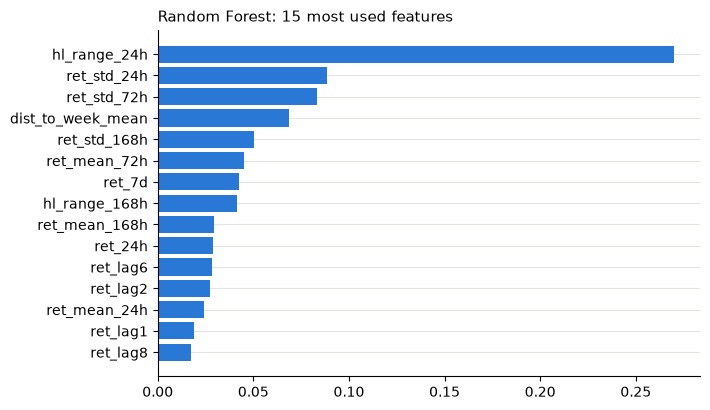

In [9]:
make_rf = lambda **p: RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE, **p)
rf_cv = val_tune(make_rf, {"max_depth": [2, 4, 8, 16], "min_samples_leaf": [20, 100, 300], "max_features": [0.3, 0.6]})
p_rf = best_params(rf_cv, ["max_depth", "min_samples_leaf", "max_features"])
rf_model = final_report(f"Random Forest {p_rf}", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **p_rf))

make_hgb_mo = lambda **p: MultiOutputRegressor(HistGradientBoostingRegressor(
    loss="absolute_error", max_iter=200, min_samples_leaf=200, early_stopping=True, random_state=RANDOM_STATE, **p))
hgb_cv = val_tune(make_hgb_mo, {"learning_rate": [0.01, 0.03, 0.1], "max_depth": [1, 2, 4]})
p_hgb = best_params(hgb_cv, ["learning_rate", "max_depth"])
GB_WIDE = f"Gradient Boosting {p_hgb}"
final_report(GB_WIDE, make_hgb_mo(**p_hgb))

fig, ax = plt.subplots(figsize=(7, 4.5))
imp = pd.Series(rf_model.feature_importances_, index=BASE).sort_values().tail(15)
ax.barh(imp.index, imp.values, color=BLUE)
tidy(ax, "Random Forest: 15 most used features")
plt.show()

"Feature importance shows which inputs the forest *uses*, not that they actually predict well. Trees also split on noise. Volatility features usually come out on top: they help the forest decide how large its forecasts should be, not which direction." *(version 1)*

**More freedom, worse validation.** The tuning tables above as curves: the train and validation skill of Ridge against its penalty, of KNN against the number of neighbours and of the Random Forest against the depth of its trees.

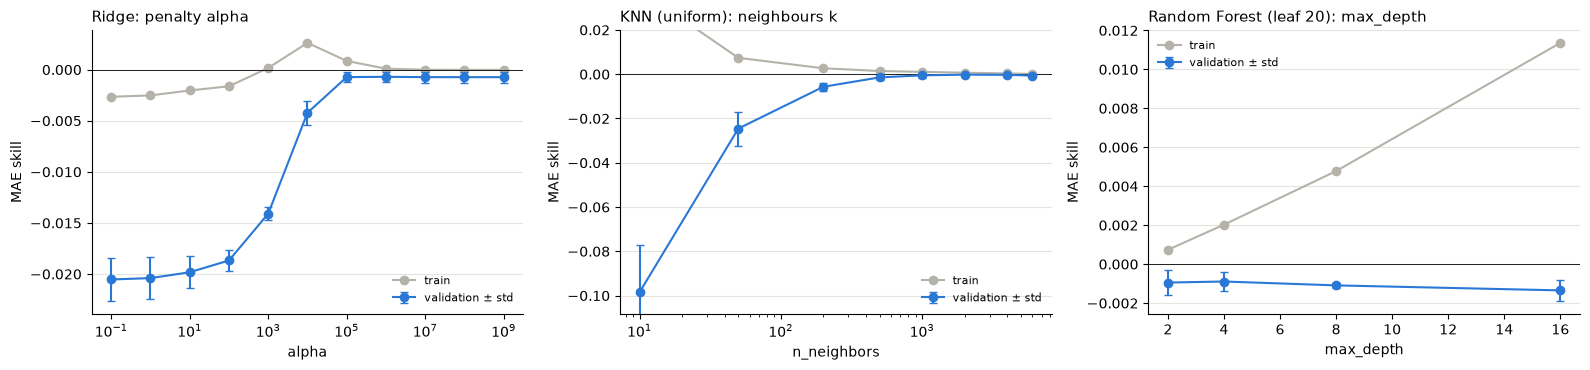

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
curves = [
    (ridge_cv.sort_values("alpha"), "alpha", "Ridge: penalty alpha", True),
    (knn_cv[knn_cv["weights"] == "uniform"].sort_values("n_neighbors"), "n_neighbors", "KNN (uniform): neighbours k", True),
    (rf_cv[(rf_cv["min_samples_leaf"] == 20) & (rf_cv["max_features"] == 0.3)].sort_values("max_depth"), "max_depth",
     "Random Forest (leaf 20): max_depth", False),
]
for a, (t, x, title, logx) in zip(ax, curves):
    a.plot(t[x], t["train_skill"], "o-", color=GREY, label="train")
    a.errorbar(t[x], t["val_skill"], yerr=t["val_skill_std"], fmt="o-", color=BLUE, capsize=3, label="validation ± std")
    a.axhline(0, color="k", lw=0.6)
    if logx:
        a.set_xscale("log")
    a.set_xlabel(x)
    a.set_ylabel("MAE skill")
    a.legend(frameon=False, fontsize=8)
    tidy(a, title)
ax[1].set_ylim(min(knn_cv["val_skill"].min(), -0.01) * 1.1, 0.02)
plt.tight_layout()
plt.show()

### 3.4 Final comparison on the test block

`DayDirAcc_indep`, `p_value` and `DayBalAcc_indep` come from the independent test days.

,MAE,RMSE,MAE_skill,R2_oos,IC,HourDirAcc,DayDirAcc_indep,p_value,DayBalAcc_indep
Model,,,,,,,,,
Baseline: last-hour reversal,0.3192,0.4925,0.0001,-0.0001,0.0020,0.4970,0.5006,0.5000,0.5006
Baseline: zero,0.3193,0.4925,-0.0000,0.0000,NaN,0.4960,0.4994,0.5277,0.5000
"Gradient Boosting {'learning_rate': 0.01, 'max_depth': 2}",0.3193,0.4926,-0.0002,-0.0006,0.0037,0.5032,0.5006,0.5000,0.5000
"Random Forest {'max_depth': 4, 'min_samples_leaf': 300, 'max_features': 0.6}",0.3194,0.4925,-0.0002,-0.0002,0.0051,0.5013,0.4970,0.5825,0.4964
Ridge {'alpha': 1000000.0},0.3194,0.4926,-0.0003,-0.0003,0.0003,0.5026,0.5006,0.5000,0.5000
Lasso {'alpha': 0.3},0.3194,0.4926,-0.0004,-0.0004,0.0000,0.5027,0.5006,0.5000,0.5000
Baseline: mean per hour,0.3194,0.4926,-0.0004,-0.0004,0.0000,0.5027,0.5006,0.5000,0.5000
"KNN {'n_neighbors': 2000, 'weights': 'distance'}",0.3194,0.4926,-0.0005,-0.0003,0.0034,0.5001,0.5103,0.2892,0.5098
Baseline: persistence,0.4736,0.6997,-0.4834,-1.0185,-0.0091,0.4957,0.4970,0.5825,0.4970


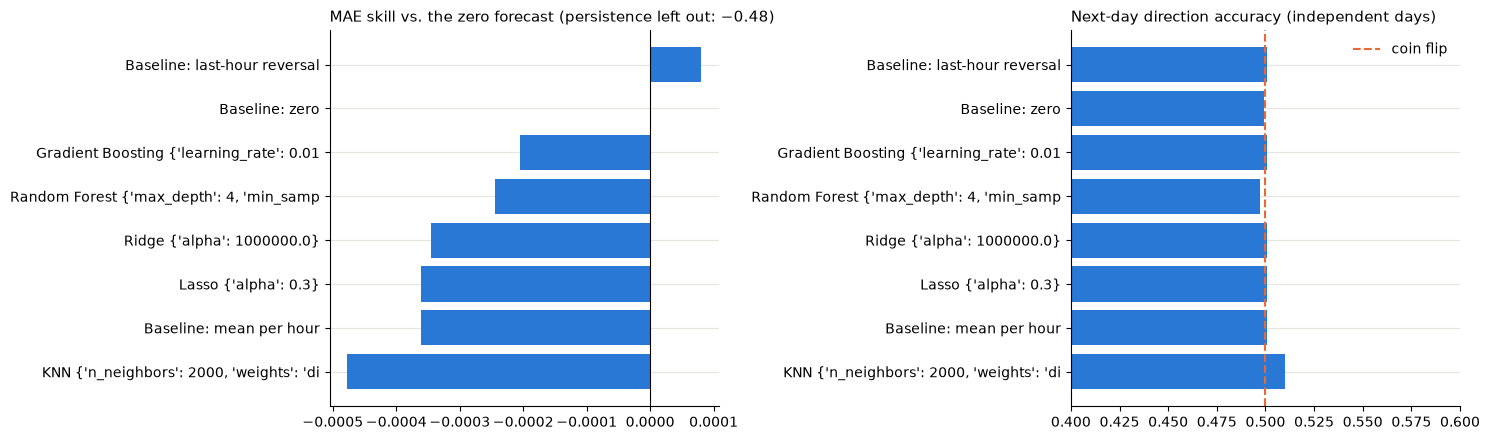

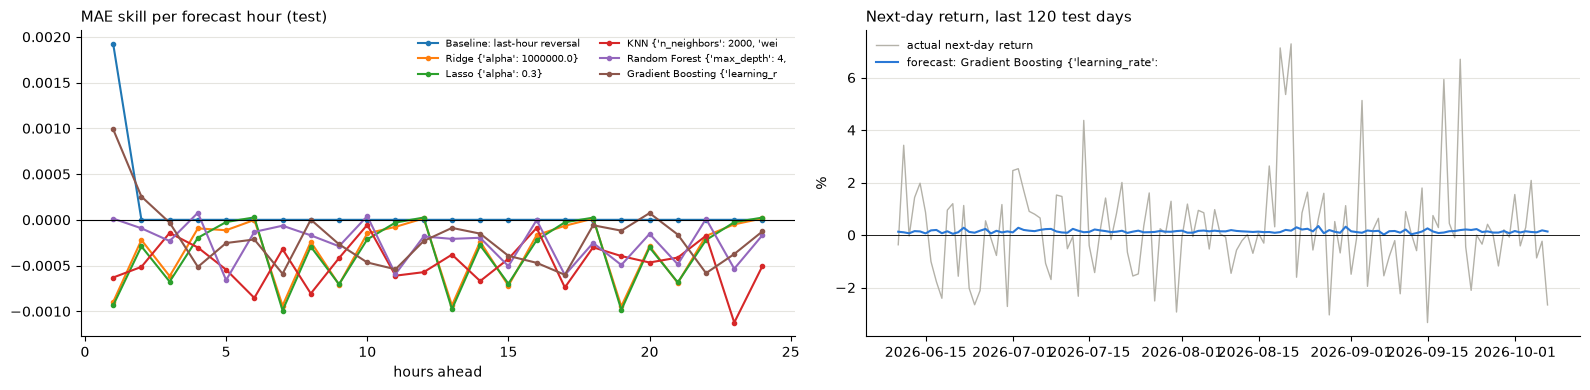

In [11]:
summary = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model")
cols = ["MAE", "RMSE", "MAE_skill", "R2_oos", "IC", "HourDirAcc", "DayDirAcc_indep", "p_value", "DayBalAcc_indep"]
display(summary[cols].sort_values("MAE").round(4))

s = summary.drop("Baseline: persistence").sort_values("MAE_skill")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(s.index.str.slice(0, 40), s["MAE_skill"], color=BLUE)
ax[0].axvline(0, color="k", lw=0.8)
tidy(ax[0], "MAE skill vs. the zero forecast (persistence left out: −0.48)")
ax[1].barh(s.index.str.slice(0, 40), s["DayDirAcc_indep"], color=BLUE)
ax[1].axvline(0.5, color=ORANGE, ls="--", label="coin flip")
ax[1].set_xlim(0.4, 0.6)
ax[1].legend(frameon=False)
tidy(ax[1], "Next-day direction accuracy (independent days)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
mae0_h = np.abs(Yte).mean(axis=0)
for name, pred in test_preds.items():
    if name.startswith("Baseline") and "reversal" not in name:
        continue
    ax[0].plot(range(1, 25), 1 - np.abs(Yte - pred).mean(axis=0) / mae0_h, marker=".", label=name[:30])
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("hours ahead")
ax[0].legend(frameon=False, fontsize=7, ncol=2)
tidy(ax[0], "MAE skill per forecast hour (test)")
best_name = summary.drop([i for i in summary.index if i.startswith("Baseline")])["MAE_skill"].idxmax()
last = test_days[-120:]
ax[1].plot(D["test"][last], U.compound(Yte[last]), color=GREY, lw=1, label="actual next-day return")
ax[1].plot(D["test"][last], U.compound(test_preds[best_name][last]), color=BLUE, lw=1.5, label=f"forecast: {best_name[:35]}")
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_ylabel("%")
ax[1].legend(frameon=False, fontsize=8)
tidy(ax[1], "Next-day return, last 120 test days")
plt.tight_layout()
plt.show()

best_tuned = summary.drop([i for i in summary.index if i.startswith("Baseline")])
SUMMARY.append({"question": "24 hourly returns (wide, v1-v2)", "chosen without the test": "best of 5 tuned models",
                "test result": f"MAE skill {best_tuned['MAE_skill'].min():+.4f} to {best_tuned['MAE_skill'].max():+.4f}",
                "simple rule": "zero forecast: 0 by definition"})

"The prediction line is almost flat compared to reality. This is not a bug: when a model cannot tell what will happen, the forecast that minimises the error is a value close to zero. The models 'know that they don't know'." *(version 1)* The right plot shows it: the forecast of the next-day return stays in a narrow band just above 0%, while the actual return moves between about −3% and +7%.

**What we see** *(`bitcoin-models-2018-2026.ipynb`, conclusions 1–3, test Jul 2024 → Oct 2026)*

1. "**The 24 hourly returns still cannot be predicted better than 'zero'.** On the test block the zero forecast has an MAE of 0.3196%. Every tuned model lands at 0.3196–0.3197%: MAE skill between −0.0002 and −0.0004, IC at most 0.005. On the validation block every setting of every model has a negative skill too."
2. "**The 'always up' illusion of version 1 is gone, and nothing replaces it.** The new test block is much more balanced (50.4% up days on the independent days, against 53.5% in version 1). The models that effectively say 'always up' now score 50.4% daily direction accuracy (p = 0.42). No model reaches significance (best: KNN 50.9%, p = 0.31). The best number belongs to a *baseline*: 'last-hour reversal' gets 52.6% with balanced accuracy 0.526, but p = 0.07, so it is not significant either. This shows how easily a lucky period makes a simple rule look good."
3. "**Hyperparameters behave exactly as in version 1: more freedom means worse validation.**
   - *Ridge / Lasso:* validation skill improves as the penalty grows, until the model becomes the 'mean per hour' forecast. [...] The best value is at the edge of the grid even after extending it twice, but this is a **plateau**: there is nothing more to find in that direction.
   - *KNN:* more neighbours is better up to k = 4000 (skill −0.0007). k = 6000 is worse again (−0.0010) because it approaches the plain average of all 7,241 training samples.
   - *Random Forest:* depth 16 with leaf 20 has train skill +0.012 but validation −0.002. The best is depth 4 with leaf 300. The differences between the shallow settings (≤ 0.0001) are far below `val_skill_std` (≈ 0.0005), so they are all equivalent.
   - *Gradient Boosting:* learning rate 0.1 with depth 4 has train skill +0.018 and validation −0.002. The best uses **depth 1** (a single split per tree, the smallest possible value) with learning rate 0.03."

   In every case, the more a model is allowed to fit the training data, the worse (or no better) it does on new periods: the signature of a target that is mostly noise.

**How much history?** Versions 1 and 2 also compared different start years of the training data (from 2012). This cannot be repeated here, because the base data starts in 2018 (`hourly-base-data.ipynb` explains why). Section 8.6 asks the question inside 2018–2022 (learning curves).

## 4. Hourly returns revisited: long format and the metric mismatch (version 3)

*Section and texts from `bitcoin-models-v3.ipynb`, sections 5 (A6), 7 (A4), 9–11 (B3, ElasticNet).*

**A6: the long format.** "Versions 1–2 used 'wide' data: one row per origin with 24 targets, so tree models needed `MultiOutputRegressor` (24 separate models, each seeing only 1/24 of the information). In the **long format** every origin becomes 24 rows, one per predicted hour, with extra columns saying *which* hour is predicted. [...] One model then learns what is common to all hours [...] and what is specific to some."

**A4: the metric mismatch.** "Versions 1–2 trained the return models with **squared error** (they learn the *mean*), but chose and judged them by **MAE**, which is minimized by the *median*. For hourly returns the median is ≈ 0, so any forecast that moves away from 0, even in the right direction, makes MAE slightly worse. A weak but real signal is therefore invisible."

Changes:
1. "**Choose by a metric that matches the loss.** For squared-error models that is **R²_oos**. The IC (correlation) is shown as a second option: it ignores the scale of the forecast and only asks 'are the hours ranked correctly?'."
2. "**A proper significance test against the zero forecast: Diebold–Mariano.** For every independent test day we compute the loss of the model and of the zero forecast, average over the 24 hours, and test whether the mean difference is > 0. The standard error uses Newey–West (robust to the autocorrelation between days)."
3. "**Confident forecasts.** A model can be useful even if it is only right when it 'speaks loudly'. On the independent test days (each actual hour counted once) we take the 10% of hours with the largest |forecast| and check the direction accuracy there, with a binomial test, plus the balanced accuracy."

Ridge and Gradient Boosting are tuned on the validation block (long format, base + per-hour columns) and chosen by each of the three criteria. Gradient Boosting uses 200 trees without early stopping (C2, section 8.1). The section-3 Gradient Boosting (wide, MAE loss, chosen by MAE skill) is the version-2 reference.

In [12]:
XA = {k: Xl(k, BASE) for k in ("train", "val", "test")}            # long format, base + per-hour columns
yr = {k: yl(k, "ret") for k in ("train", "val", "test")}
XA_tv, yr_tv = np.vstack([XA["train"], XA["val"]]), np.r_[yr["train"], yr["val"]]
print(f"Long format: train {len(yr['train']):,} rows, validation {len(yr['val']):,}, test {len(yr['test']):,}")

ret_ridge_t, _ = tune(make_ridge, {"alpha": [0.1, 10, 1e3, 1e5, 1e6, 1e7, 1e8]}, XA["train"], yr["train"], XA["val"], yr["val"], ret_scores)
ret_gb_t, _ = tune(make_gb, {"learning_rate": [0.03, 0.1], "max_depth": [2, 6], "min_samples_leaf": [200, 2000]},
                   XA["train"], yr["train"], XA["val"], yr["val"], ret_scores)


def pick(table, col, keys):
    return as_int(table.loc[table[col].idxmax(), keys].to_dict())


choices = {}
for name, t, keys in [("Ridge", ret_ridge_t, ["alpha"]), ("Gradient Boosting", ret_gb_t, ["learning_rate", "max_depth", "min_samples_leaf"])]:
    for crit, col in [("MAE skill", "MAE_skill"), ("R2_oos", "score"), ("IC", "IC")]:
        choices[(name, crit)] = pick(t, col, keys)
display(pd.DataFrame({f"{n} chosen by {c}": v for (n, c), v in choices.items()}).T)

Long format: train 171,576 rows, validation 51,672, test 477,024


,alpha,score,MAE_skill,IC,seconds
0,100000000.0,0.0004,0.0003,0.0121,0.2
1,10000000.0,0.0004,0.0003,0.0126,0.2
2,1000000.0,0.0003,0.0003,0.0151,0.2
3,100000.0,0.0001,-0.0001,0.0164,0.2
4,1000.0,-0.0006,-0.0010,0.0147,0.2
5,0.1,-0.0006,-0.0010,0.0146,0.2
6,10.0,-0.0006,-0.0010,0.0146,0.2


,learning_rate,max_depth,min_samples_leaf,score,MAE_skill,IC,seconds
0,0.03,2,2000,0.0005,0.0001,0.0179,1.7
1,0.03,2,200,0.0005,0.0001,0.0171,1.7
2,0.03,6,2000,0.0005,-0.0005,0.0229,2.6
3,0.03,6,200,0.0002,-0.0012,0.0234,2.9
4,0.10,2,2000,-0.0000,-0.0009,0.0172,1.7
5,0.10,2,200,-0.0004,-0.0014,0.0136,1.8
6,0.10,6,2000,-0.0037,-0.0049,0.0090,2.6
7,0.10,6,200,-0.0042,-0.0069,0.0192,2.9


,alpha,learning_rate,max_depth,min_samples_leaf
Ridge chosen by MAE skill,10000000.0,NaN,NaN,NaN
Ridge chosen by R2_oos,100000000.0,NaN,NaN,NaN
Ridge chosen by IC,100000.0,NaN,NaN,NaN
Gradient Boosting chosen by MAE skill,NaN,0.03,2.0,2000.0
Gradient Boosting chosen by R2_oos,NaN,0.03,2.0,2000.0
Gradient Boosting chosen by IC,NaN,0.03,6.0,200.0


**Test block.** Each choice is refitted on train + validation and evaluated once. Columns:
- `MAE_skill`, `R2_oos`, `IC`: as in section 3.
- `DM_p_sq` / `DM_p_abs`: Diebold–Mariano p-value for "the model has a lower squared / absolute error than the zero forecast" (independent days).
- `conf_n`, `conf_acc`, `conf_bal_acc`, `conf_p`: number of hours, direction accuracy, balanced accuracy and binomial p-value on the 10% most confident hourly forecasts (independent days only).

"*Why only independent days?* In the test block each actual hour appears in 24 rows (it is hour 1 of one origin, hour 2 of the previous one, …). Counting it 24 times would make a binomial test far too confident."

**ElasticNet** (version 3, C4) combines Lasso's feature removal with Ridge's shrinkage. It is added with the per-hour features **B3** (section 1.3) and the setting version 3 chose by walk-forward R²_oos (`alpha=0.01, l1_ratio=0.5`).

ElasticNet on validation: R2_oos +0.0004, IC +0.0187
ElasticNet (train + validation) keeps 4 of 52 features: ['ret_lag12', 'pos_in_week_range', 'hl_range_24h', 'ret_same_hour_1d']


,MAE_skill,R2_oos,IC,DM_p_sq,DM_p_abs,conf_n,conf_acc,conf_bal_acc,conf_p
Baseline: zero,0.0000,0.0000,NaN,NaN,NaN,0.0,NaN,NaN,NaN
"Version-2 style: wide GB, MAE loss (section 3)",-0.0002,-0.0006,0.0037,0.9791,0.8929,2251.0,0.5020,0.5015,0.4331
"Ridge {'alpha': 10000000.0}, chosen by MAE skill",-0.0000,0.0000,0.0129,0.4851,0.5062,1989.0,0.5128,0.5000,0.1311
"Ridge {'alpha': 100000000.0}, chosen by R2_oos",-0.0000,-0.0000,0.0129,0.5493,0.5840,1989.0,0.5113,0.5000,0.1619
"Ridge {'alpha': 100000.0}, chosen by IC",-0.0002,0.0000,0.0105,0.4883,0.6988,1986.0,0.5287,0.5171,0.0056
"Gradient Boosting {'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 2000}, chosen by MAE skill / R2_oos",0.0000,0.0003,0.0175,0.1616,0.3227,1986.0,0.5176,0.4996,0.0608
"Gradient Boosting {'learning_rate': 0.03, 'max_depth': 6, 'min_samples_leaf': 200}, chosen by IC",-0.0010,-0.0008,0.0106,0.7068,0.9937,1987.0,0.4987,0.5015,0.5535
ElasticNet (base + B3),-0.0002,-0.0001,0.0103,0.5867,0.6886,1986.0,0.5096,0.5117,0.2032


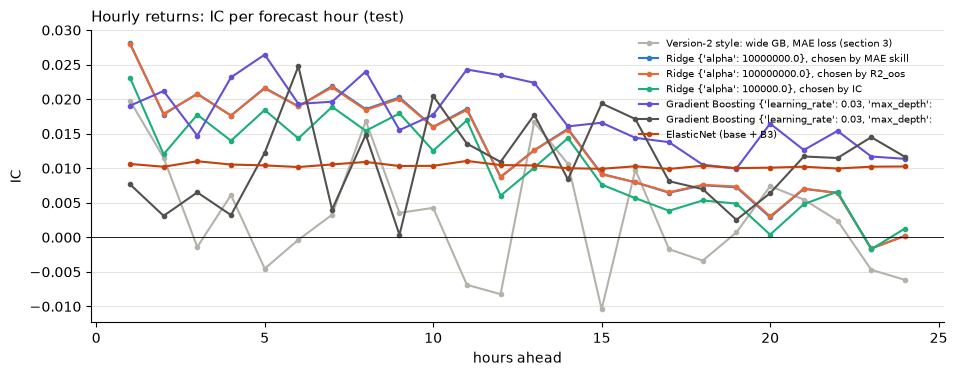

In [13]:
def daily_loss(y, p, kind):
    e = (y - p) ** 2 if kind == "sq" else np.abs(y - p)
    return e.reshape(-1, 24)[test_days].mean(axis=1)                 # one loss per independent test day


def ret_test_report(pred, y=None):
    y = yr["test"] if y is None else y
    m = ret_scores(y, pred)
    out = {"MAE_skill": m["MAE_skill"], "R2_oos": m["score"], "IC": m["IC"]}
    for kind in ("sq", "abs"):
        out[f"DM_p_{kind}"] = np.nan if not pred.any() else \
            U.diebold_mariano(daily_loss(y, 0 * pred, kind), daily_loss(y, pred, kind))[2]
    ind = rows24(test_days)                                          # every actual hour counted once
    pi, yi = pred[ind], y[ind]
    top = (np.abs(pi) >= np.quantile(np.abs(pi), 0.9)) & (yi != 0) & (pi != 0)
    hits = np.sign(pi[top]) == np.sign(yi[top])
    out["conf_n"] = int(top.sum())
    out["conf_acc"] = hits.mean() if top.any() else np.nan
    out["conf_bal_acc"] = balanced_accuracy_score(yi[top] > 0, pi[top] > 0) if top.any() else np.nan
    out["conf_p"] = stats.binomtest(int(hits.sum()), int(top.sum()), 0.5, alternative="greater").pvalue if top.any() else np.nan
    return out


ret_pred_te = {"Version-2 style: wide GB, MAE loss (section 3)": test_preds[GB_WIDE].reshape(-1)}
fitted = {}
for (name, crit), p in choices.items():
    key = (name, str(p))
    if key not in fitted:
        m = make_ridge(**p) if name == "Ridge" else make_gb(**p)
        fitted[key] = [m.fit(XA_tv, yr_tv).predict(XA["test"]), []]
    fitted[key][1].append(crit)
for (name, ps), (pred, crits) in fitted.items():
    ret_pred_te[f"{name} {ps}, chosen by {' / '.join(crits)}"] = pred

XR = {k: Xl(k, BASE, H_BASE + B3) for k in ("train", "val", "test")}   # long format, base + per-hour + B3
XR_tv = np.vstack([XR["train"], XR["val"]])
make_en = lambda: make_pipeline(StandardScaler(), ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=3000))
en_va = make_en().fit(XR["train"], yr["train"]).predict(XR["val"])
en_model = make_en().fit(XR_tv, yr_tv)
names_r = BASE + H_BASE + B3
print(f"ElasticNet on validation: R2_oos {U.r2_oos(yr['val'], en_va):+.4f}, IC {safe_corr(en_va, yr['val']):+.4f}")
print(f"ElasticNet (train + validation) keeps {(en_model[-1].coef_ != 0).sum()} of {len(names_r)} features:",
      [n for n, c in zip(names_r, en_model[-1].coef_) if c != 0])
ret_pred_te["ElasticNet (base + B3)"] = en_model.predict(XR["test"])

ret_rows = {"Baseline: zero": ret_test_report(np.zeros_like(yr["test"]))}
ret_rows.update({k: ret_test_report(v) for k, v in ret_pred_te.items()})
ret_tab = pd.DataFrame(ret_rows).T
display(ret_tab.round(4))

fig, ax = plt.subplots(figsize=(11, 3.8))
ac = yr["test"].reshape(-1, 24)
for (k, v), c in zip(ret_pred_te.items(), [GREY, BLUE, ORANGE, AQUA, PURPLE, INK, "#c2410c", "#0e7490", "#a16207"]):
    pr = v.reshape(-1, 24)
    ax.plot(range(1, 25), [safe_corr(pr[:, j], ac[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k[:55])
ax.axhline(0, c="k", lw=0.6)
ax.set_xlabel("hours ahead")
ax.set_ylabel("IC")
ax.legend(frameon=False, fontsize=7)
tidy(ax, "Hourly returns: IC per forecast hour (test)")
plt.show()

SUMMARY.append({"question": "24 hourly returns (long, v3)", "chosen without the test": "Ridge / GB by MAE, R2_oos or IC; ElasticNet",
                "test result": f"IC {ret_tab['IC'].min():.3f} to {ret_tab['IC'].max():.3f}, best DM p (sq) {ret_tab['DM_p_sq'].min():.2f}",
                "simple rule": "zero forecast"})

**What we see** *(`bitcoin-models-v3.ipynb`, sections 7 and 11)*

- "**Different criteria choose different models.** For Ridge, MAE skill and R²_oos both prefer an enormous penalty (alpha 10⁷–10⁸, i.e. a forecast ≈ the training average), while the IC prefers alpha = 10⁵, which keeps some information. [...] Note how close everything is: the whole HGB table lies within 0.0002 of R²_oos. Validation can barely tell these settings apart."
- "**Choosing by R²_oos/IC helps a little.** The Gradient Boosting chosen by R²_oos is the only return model with a positive R²_oos (+0.0004), and its IC is **0.020**, four times the version-2 reference (0.005). The IC plot shows it positive at every horizon (0.01–0.03), while the reference jumps around 0."
- "**It is still not significant.** The Diebold–Mariano test against the zero forecast gives p = 0.13 (squared error) and 0.41 (absolute error)."
- "**Confident forecasts:** on the 10% most confident hours, accuracy is 51–52% and balanced accuracy 50–51%. [...] with 8 models tested one p-value of 0.03 is expected by pure chance (multiple testing)."
- ElasticNet "keeps only **5 of 52 features**: two lagged returns, the position in the week's range, the 24 h High–Low range, and `ret_same_hour_1d` (the lag-24 reversal [...]). It has the best walk-forward R²_oos of all return models (+0.0010, positive in all 4 folds), but on test it falls to −0.0001 (IC 0.010, DM p = 0.60). The pattern is the same as everywhere for returns: what looks stable on 5 years of history does not survive into the next 2 years."

"**Conclusion of A4:** the metric mismatch was real. With the matching criterion the models keep a small positive signal (IC ≈ 0.02) instead of throwing it away. But the signal is far too small to be statistically reliable on 827 test days. The honest summary for hourly returns is: *weak positive ranking information, not significant.*"

**Not rerun here:** the volatility-scaled target (r / σ), 1/σ² sample weights and the Huber loss of version 3 (A5, C3); see section 12.7.

## 5. The direction of the next hour

*Section and texts from `v3-extensions.ipynb`, section 5.*

"Alberto (section 4 of v3) found the reversal at lag 1 but called it unstable. Here the same question on his blocks":

- "**Reversal rule:** 'the next hour goes the opposite way of the last hour', no learning."
- "**Gradient Boosting classifier** for 'next hour up?', on base features and on base + all Binance attributes, tuned on validation by AUC."

"Metrics on every test hour (≈ 19,800): AUC, and the accuracy on the 10% most confident forecasts (binomial test against 50%)."

**Binance attributes** (`utils/binance.py`, built in `v3-extensions.ipynb`): **order flow** (share of taker buys at several horizons, net flow, number and size of trades), **ETH** (returns, volatility, buy share and volume of ETHUSDT) and **ETH vs BTC** (relative returns, rolling correlation and beta, position of the ETH/BTC ratio in its weekly range). They are added to `FEAT` here and used again in section 6. The alignment check compares Binance's hourly BTC change with `ret_lag1`, computed from the base data.

In [14]:
btc, eth = load_binance("BTCUSDT"), load_binance("ETHUSDT")
groups = build_attributes(btc, eth)
G = {g: list(t.columns) for g, t in groups.items()}
BINANCE = G["flow"] + G["eth"] + G["cross"]
FEAT = pd.concat([FEAT] + [t.reindex(hourly.index) for t in groups.values()], axis=1)    # Xw() and Xl() read FEAT
assert all(np.isfinite(FEAT[BINANCE].values[P[k]]).all() for k in P), "missing Binance attributes"
c = safe_corr(btc["ret"].reindex(hourly.index[P["test"]]), FEAT["ret_lag1"].values[P["test"]])
print(f"Binance attributes: flow {len(G['flow'])}, eth {len(G['eth'])}, cross {len(G['cross'])} | alignment check corr = {c:.4f}")
assert c > 0.95

y1 = {k: Y[k][:, 0] for k in P}                                      # the next hour's return


def direction_row(score, y):
    nz = y != 0
    score, y = score[nz], y[nz]
    centred = score - np.median(score)
    top = np.argsort(-np.abs(centred))[:len(score) // 10]
    hits = (centred[top] > 0) == (y[top] > 0)
    return {"AUC": roc_auc_score(y > 0, score), "accuracy top 10%": hits.mean(),
            "p-value": stats.binomtest(int(hits.sum()), len(top), 0.5, alternative="greater").pvalue}


dir_rows = {"Reversal rule": {"val AUC": roc_auc_score(y1["val"] > 0, -FEAT["ret_lag1"].values[P["val"]]),
                              **direction_row(-FEAT["ret_lag1"].values[P["test"]], y1["test"])}}
dir_scores = {"Reversal rule": -FEAT["ret_lag1"].values[P["test"]]}
make_clf = lambda **p: HistGradientBoostingClassifier(early_stopping=False, max_iter=200, random_state=RANDOM_STATE, **p)
for name, cols in {"GB classifier, base": BASE, "GB classifier, base + Binance": BASE + BINANCE}.items():
    Xtr_, Xva_, Xte_ = Xw("train", cols), Xw("val", cols), Xw("test", cols)
    val_auc = {tuple(p.items()): roc_auc_score(y1["val"] > 0, make_clf(**p).fit(Xtr_, y1["train"] > 0).predict_proba(Xva_)[:, 1])
               for p in ParameterGrid({"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "min_samples_leaf": [200, 1000]})}
    p = dict(max(val_auc, key=val_auc.get))
    clf = make_clf(**p).fit(np.vstack([Xtr_, Xva_]), np.r_[y1["train"], y1["val"]] > 0)
    dir_scores[name] = clf.predict_proba(Xte_)[:, 1]
    dir_rows[f"{name} {p}"] = {"val AUC": max(val_auc.values()), **direction_row(dir_scores[name], y1["test"])}
dir_tab = pd.DataFrame(dir_rows).T
display(dir_tab.style.format({"val AUC": "{:.4f}", "AUC": "{:.4f}", "accuracy top 10%": "{:.3f}", "p-value": "{:.1e}"}))

best_dir = dir_tab.drop("Reversal rule")["val AUC"].idxmax()
SUMMARY.append({"question": "direction of the next hour", "chosen without the test": best_dir.split(" {")[0],
                "test result": f"AUC {dir_tab.loc[best_dir, 'AUC']:.3f}, top 10% right {dir_tab.loc[best_dir, 'accuracy top 10%']:.1%} "
                               f"(p = {dir_tab.loc[best_dir, 'p-value']:.0e})",
                "simple rule": f"reversal rule: AUC {dir_tab.loc['Reversal rule', 'AUC']:.3f}"})

Binance attributes: flow 14, eth 12, cross 8 | alignment check corr = 0.9987


,val AUC,AUC,accuracy top 10%,p-value
Reversal rule,0.5460,0.5278,0.546,2.4e-05
"GB classifier, base {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 200}",0.5596,0.5377,0.552,1.6e-06
"GB classifier, base + Binance {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 1000}",0.5618,0.5403,0.566,2.9e-09


**What we see** *(`v3-extensions.ipynb`, section 5)*

- "**The reversal is stable.** On Alberto's test block (Jul 2024 → Oct 2026, a period none of my earlier choices saw) the simple rule still has AUC **0.528**, and its 10% most confident forecasts are right **54.6%** of the time (p = 3×10⁻⁵)."
- "**Gradient Boosting adds a little:** AUC **0.537** on base features. With the Binance attributes the AUC is the same (0.537), but the most confident 10% are right **55.5%** of the time (p = 6×10⁻⁷)."
- "This is a real but small effect for **one hour ahead only**: about 55 correct out of 100 confident calls, before any trading costs."

`data-analysis.ipynb` (section 4) checks the reversal year by year on train and validation: the lag-1 autocorrelation is negative in most years but close to 0 in 2019, 2021, 2022 and 2024.

## 6. The size of each hourly move

*Section and texts from `bitcoin-models-v3.ipynb`, sections 5 (A2 + A6), 8–9 (B1–B3), 11 (C4, C5), and `v3-extensions.ipynb`, sections 2–3.*

"Section 4 [of version 3, section 4 of `data-analysis.ipynb`] shows that the **size** of hourly moves is strongly autocorrelated while the direction is not. So, next to the return target, we predict **|r_h|: the absolute return of each of the 24 next hours**, in %. This keeps the structure of the assigned task (24 hourly values for tomorrow) but asks the question the data can answer: *how much will each hour move?*"

"The models are trained with squared error, so they predict the expected size of the move. The main metric is the usual **R²** (share of the hour-to-hour variation explained)."

**Baselines** (no learning):
- *Training mean*: the same value for every hour.
- *Last week*: the average |r| of the last 168 hours.
- *Same hour yesterday*: |r| 24 hours before the predicted hour.
- *Last week × hour profile*: last week's average |r| multiplied by the intraday pattern. "This is the strongest simple rule."

### 6.1 Models on the validation block

Ridge, Random Forest, Extra Trees and Gradient Boosting on the long format (base features + per-hour columns), each with a small grid around the settings version 3 found. Gradient Boosting uses 200 trees without early stopping (C2, section 8.1). The tree ensembles use `max_samples=0.2` (each tree sees a random 20% of the rows), which keeps them fast on ≈170,000 rows. *Extra Trees* "is like Random Forest, but split thresholds are drawn at random: more variety, often less overfitting" (version 3, C4).

In [15]:
ya = {k: yl(k) for k in ("train", "val", "test")}
ya_tv = np.r_[ya["train"], ya["val"]]


def abs_baselines(block):
    p = np.repeat(P[block], 24)
    h_ = np.tile(np.arange(1, 25), len(P[block]))
    return {"Baseline: training mean": np.full(len(p), ya["train"].mean()),
            "Baseline: last week": week_abs[p],
            "Baseline: same hour yesterday": absr[p + h_ - 24],
            "Baseline: last week x hour profile": rule_abs(block)}


print("Baselines on the validation block")
display(pd.DataFrame({k: vol_scores(ya["val"], v) for k, v in abs_baselines("val").items()}).T.rename(columns={"score": "R2"}).round(4))

make_abs_gb = lambda **p: make_gb(min_samples_leaf=1000, **p)
make_rf_l = lambda **p: RandomForestRegressor(n_estimators=100, max_samples=0.2, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE, **p)
make_et_l = lambda **p: ExtraTreesRegressor(n_estimators=60, max_samples=0.2, max_features=0.5, bootstrap=True, n_jobs=-1,
                                            random_state=RANDOM_STATE, **p)
abs_models = {"Ridge": (make_ridge, {"alpha": [0.01, 1, 100, 10_000]}),
              "Random Forest": (make_rf_l, {"max_depth": [14, 20], "min_samples_leaf": [20, 200]}),
              "Extra Trees": (make_et_l, {"max_depth": [16, 24], "min_samples_leaf": [20, 50]}),
              "Gradient Boosting": (make_abs_gb, {"learning_rate": [0.05, 0.1], "max_depth": [2, 3, 6]})}
abs_best = {}
for name, (mk, grid) in abs_models.items():
    print(name)
    _, abs_best[name] = tune(mk, grid, XA["train"], ya["train"], XA["val"], ya["val"], vol_scores)
p_abs_gb = abs_best["Gradient Boosting"]

Baselines on the validation block


,R2,MAE,corr
Baseline: training mean,-0.2217,0.3375,NaN
Baseline: last week,0.0355,0.2311,0.2021
Baseline: same hour yesterday,-0.7487,0.2989,0.1256
Baseline: last week x hour profile,0.0481,0.2285,0.2279


Ridge


,alpha,score,MAE,corr,seconds
0,0.01,0.0865,0.2192,0.2955,0.2
1,1.00,0.0865,0.2192,0.2955,0.2
2,100.00,0.0856,0.2196,0.2940,0.2
3,10000.00,0.0795,0.2255,0.2834,0.2


Random Forest


,max_depth,min_samples_leaf,score,MAE,corr,seconds
0,14,200,0.0796,0.2263,0.2833,2.9
1,20,200,0.0792,0.2263,0.2826,2.9
2,14,20,0.0757,0.2287,0.2805,3.6
3,20,20,0.0746,0.2293,0.2803,4.1


Extra Trees


,max_depth,min_samples_leaf,score,MAE,corr,seconds
0,16,50,0.0863,0.2262,0.2960,1.0
1,24,50,0.0860,0.2262,0.2954,1.2
2,24,20,0.0841,0.2269,0.2933,1.2
3,16,20,0.0827,0.2270,0.2906,1.1


Gradient Boosting


,learning_rate,max_depth,score,MAE,corr,seconds
0,0.10,2,0.0908,0.2227,0.3020,1.8
1,0.10,3,0.0901,0.2220,0.3015,2.0
2,0.05,3,0.0896,0.2236,0.3004,2.0
3,0.05,2,0.0890,0.2253,0.3003,1.8
4,0.05,6,0.0866,0.2232,0.2963,2.7
5,0.10,6,0.0833,0.2233,0.2932,2.7


### 6.2 A6 on its own: long vs. wide

"The same HistGradientBoosting setting is trained the old way, with `MultiOutputRegressor` (24 models on the wide data, one per hour), on the same target. Comparing the validation R² and the training time isolates the effect of the long format." *(version 3)*

In [16]:
t0 = time.time()
wide = MultiOutputRegressor(make_abs_gb(**p_abs_gb)).fit(Ftr, np.abs(Ytr))
t_wide = time.time() - t0
t0 = time.time()
long_m = make_abs_gb(**p_abs_gb).fit(XA["train"], ya["train"])
t_long = time.time() - t0
display(pd.DataFrame({"wide (24 models)": {**vol_scores(ya["val"], wide.predict(Fva).reshape(-1)), "train seconds": t_wide},
                      "long (1 model)": {**vol_scores(ya["val"], long_m.predict(XA["val"])), "train seconds": t_long}}).T
        .rename(columns={"score": "val R2"}).round(4))

,val R2,MAE,corr,train seconds
wide (24 models),0.0633,0.2300,0.2672,3.8877
long (1 model),0.0908,0.2227,0.3020,1.6039


### 6.3 Test block

The best setting of each model is refitted on train + validation and evaluated once on the test block (every origin × 24 hours). *Ensemble* is the average of Ridge, Extra Trees and Gradient Boosting (version 3, C5): "Ridge and the trees make *different* errors (linear vs. non-linear), and averaging cancels part of them."

,R2,MAE,corr
Baseline: training mean,-0.1953,0.3248,NaN
Baseline: last week,0.0377,0.2369,0.2087
Baseline: same hour yesterday,-0.6833,0.3045,0.1585
Baseline: last week x hour profile,0.0529,0.2349,0.2386
Ridge,0.0952,0.2257,0.3097
Random Forest,0.1083,0.2245,0.3296
Extra Trees,0.1170,0.2236,0.3432
Gradient Boosting,0.1167,0.2225,0.3420
"Ensemble (Ridge, Extra Trees, GB)",0.1153,0.2228,0.3404


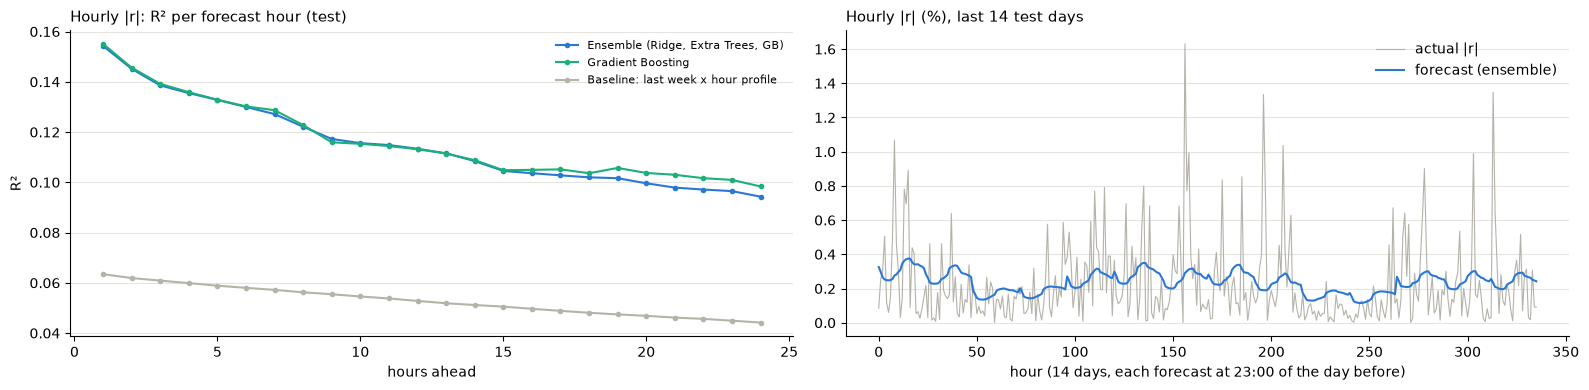

In [17]:
abs_test_pred = dict(abs_baselines("test"))
for name, (mk, _) in abs_models.items():
    abs_test_pred[name] = mk(**abs_best[name]).fit(XA_tv, ya_tv).predict(XA["test"])
abs_test_pred["Ensemble (Ridge, Extra Trees, GB)"] = np.mean([abs_test_pred[k] for k in ("Ridge", "Extra Trees", "Gradient Boosting")], axis=0)
abs_tab = pd.DataFrame({k: vol_scores(ya["test"], v) for k, v in abs_test_pred.items()}).T.rename(columns={"score": "R2"})
display(abs_tab.round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ac = ya["test"].reshape(-1, 24)
for k, c in [("Ensemble (Ridge, Extra Trees, GB)", BLUE), ("Gradient Boosting", AQUA), ("Baseline: last week x hour profile", GREY)]:
    pr = abs_test_pred[k].reshape(-1, 24)
    ax[0].plot(range(1, 25), [U.r2(ac[:, j], pr[:, j]) for j in range(24)], "o-", ms=3, color=c, label=k)
ax[0].set_xlabel("hours ahead")
ax[0].set_ylabel("R²")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Hourly |r|: R² per forecast hour (test)")
seg = test_days[-14:]                                                # last 14 days, one origin per day
ax[1].plot(np.abs(Yte[seg]).reshape(-1), lw=0.8, color=GREY, label="actual |r|")
ax[1].plot(abs_test_pred["Ensemble (Ridge, Extra Trees, GB)"].reshape(-1, 24)[seg].reshape(-1), lw=1.5, color=BLUE, label="forecast (ensemble)")
ax[1].set_xlabel("hour (14 days, each forecast at 23:00 of the day before)")
ax[1].legend(frameon=False)
tidy(ax[1], "Hourly |r| (%), last 14 test days")
plt.tight_layout()
plt.show()

**What we see** *(`bitcoin-models-v3.ipynb`, sections 5 and 11)*

- *Baselines:* "The 'last week × hour profile' rule is the best simple rule (R² 0.048). 'Same hour yesterday' is very bad (R² −0.75): one single hour is an extremely noisy estimate of volatility. The training mean is also negative (−0.22), because the validation period (2023–mid 2024) was much calmer than 2018–2022: R² penalizes a wrong *level*, not only a wrong pattern."
- "**A6 on its own: the long format raises the validation R² from 0.064 to 0.092 (+43%)**, with the same model, the same features and the same training time. The 24 separate models of the wide format each see only their own hour. The single long-format model learns the common structure ('volatile weeks make every hour volatile') from 24× more rows, and the hour-specific part from the per-hour columns."
- "**Test block results (A2 + A6).** Gradient Boosting explains **11.7% of the hour-to-hour variation in the size of the move** (Random Forest 10.8%, Ridge 9.5%), about **2.2× the best simple rule** (5.3%). The correlation between forecast and actual size is 0.34."
- "**Left plot:** the skill is highest for the next hour (R² ≈ 0.16) and slowly decreases to ≈ 0.10 at 24 hours ahead, as expected: the further ahead, the less the recent volatility tells. The model beats the rule at every horizon."
- "**Right plot:** the forecast follows the calm and agitated periods and the intraday rhythm, but not the individual spikes. Single extreme hours are news-driven and not predictable, which is why R² stays far below 1. An R² of ≈0.12 for *hourly* volatility is a good result."
- *Ensemble (C5):* on the walk-forward folds "the ensemble **does** help [...]: 0.119 against 0.111 for each model alone (+7%). [...] On test the three single models and the ensemble are within 0.003 of each other (0.116–0.119), clearly above Ridge alone (0.095)."

### 6.4 Which inputs help? Feature groups and other markets

Each feature group is added on its own to the base features, with the Gradient Boosting setting of 6.1 fixed, so only the inputs change (version 3, section 8; `v3-extensions.ipynb`, section 2). The Binance groups are compared with **base + B3**, the reference of `v3-extensions.ipynb`. The validation R² is the one to choose by; the test R² is shown as in `v3-extensions.ipynb`, for information only.

In [18]:
SETS = {"base": (BASE, H_BASE), "base + B1 (30-day history)": (BASE + B1, H_BASE),
        "base + B2 (range volatility)": (BASE + B2, H_BASE), "base + B3 (per-hour)": (BASE, H_BASE + B3),
        "base + B3 + order flow": (BASE + G["flow"], H_BASE + B3), "base + B3 + ETH": (BASE + G["eth"], H_BASE + B3),
        "base + B3 + ETH vs BTC": (BASE + G["cross"], H_BASE + B3), "base + B3 + all Binance": (BASE + BINANCE, H_BASE + B3)}
feat_rows = []
for name, (cols, hcols) in SETS.items():
    Xtr_l, Xva_l = Xl("train", cols, hcols), Xl("val", cols, hcols)
    r_val = U.r2(ya["val"], make_abs_gb(**p_abs_gb).fit(Xtr_l, ya["train"]).predict(Xva_l))
    r_test = U.r2(ya["test"], make_abs_gb(**p_abs_gb).fit(np.vstack([Xtr_l, Xva_l]), ya_tv).predict(Xl("test", cols, hcols)))
    feat_rows.append({"features": name, "n_features": Xtr_l.shape[1], "val R2": r_val, "test R2": r_test})
    del Xtr_l, Xva_l
display(pd.DataFrame(feat_rows).set_index("features").round(4))

,n_features,val R2,test R2
features,,,
base,47,0.0908,0.1167
base + B1 (30-day history),54,0.0929,0.1184
base + B2 (range volatility),53,0.0854,0.1175
base + B3 (per-hour),52,0.0916,0.1212
base + B3 + order flow,66,0.0907,0.1208
base + B3 + ETH,64,0.0926,0.1210
base + B3 + ETH vs BTC,60,0.0892,0.1222
base + B3 + all Binance,86,0.0889,0.1192


**What we see**

*(`bitcoin-models-v3.ipynb`, sections 8–9, walk-forward)* "**Hourly |r|:** all feature sets score 0.108–0.112, while the spread between folds is ±0.011. The features make no real difference." On the single validation block "**B1 (30-day history) and B2 (range-based volatility) do not help** [...]. The likely reason is that the base features already contain the same information (std of returns over 24/72/168 h, High–Low range), and more correlated features give the trees more ways to fit noise."

*(`v3-extensions.ipynb`, section 2)* "The Binance attributes do not change the result. Gradient Boosting on Alberto's base features reaches test R² **0.123**; with order flow, ETH or ETH vs BTC it stays between 0.121 and 0.126. On validation the differences are also ≤ 0.002, smaller than the effect of a different hyperparameter setting. [...] The size of the next hours' moves is already described by Bitcoin's own recent volatility and the clock; ETH and order flow repeat the same information."

*(version 3, B4, not rerun)* Permutation importance put the **average High–Low range** of the last 24 hours and of the last week and the **calendar** (hour profile and weekday of the predicted hour) on top; most individual lagged returns had importance ≈ 0.

### 6.5 Refitting every month, with more weight on recent data

*(`v3-extensions.ipynb`, section 3)* "Alberto's models are fitted once (mid-2024) and used for 2¼ years. In practice a model would be refitted regularly on everything known at that time. This matters here: the daily rhythm of volatility changed after 2024" (the 14 UTC peak grew from 1.2× to 1.7× the average hour after the spot ETFs, `data-analysis.ipynb`, section 5).

"**Simulation.** For every month of the evaluation period, Gradient Boosting (base + per-hour features [...]) is refitted on all origins whose 24 target hours ended **before the month starts** (every 6th origin since 2018), and predicts that month."

| Variant | Training rows |
|---|---|
| Fit once | train (+ validation, for the test block) |
| Monthly, expanding | everything before the month |
| Monthly, last 24 months | a rolling window |
| Monthly, half-life 6 / 12 months | everything, with weight `0.5 ** (age in months / half-life)` |

"The variant is **chosen on the validation block** (the same simulation over Jan 2023 → Jun 2024) and then run once on test." Features: base + per-hour + B3; model: the Gradient Boosting setting of 6.1. (`v3-extensions.ipynb` also tried a 12-month window and a 24-month half-life; they are left out to save time.)

In [19]:
HC = H_BASE + B3
pool = np.arange(len(origins))[::STRIDE]
P["pool"], Y["pool"], D["pool"] = pos_all[pool], y_all[pool], origins[pool]
X_pool, y_pool = Xl("pool", BASE, HC), yl("pool")
pool_end, pool_origin = np.repeat(day_end[pool], 24), np.repeat(origins[pool], 24)
make_gb_refit = lambda: make_abs_gb(**p_abs_gb)

REFIT = {"Monthly, expanding": {}, "Monthly, last 24 months": {"window": 24},
         "Monthly, half-life 6 months": {"half_life": 6}, "Monthly, half-life 12 months": {"half_life": 12}}


def month_fit_rows(start, window=None, half_life=None):
    fit = pool_end < start                                           # targets known before the month
    if window:
        fit &= pool_origin >= start - pd.DateOffset(months=window)
    w = 0.5 ** ((start - pool_origin[fit]) / pd.Timedelta(days=30.44) / half_life) if half_life else None
    return fit, w


def refit_monthly(block, X_b, **kw):
    org = np.repeat(D[block], 24)
    pred = np.empty(len(X_b))
    for m in pd.period_range(D[block][0], D[block][-1], freq="M"):
        start = m.start_time
        fit, w = month_fit_rows(start, **kw)
        rows_m = (org >= start) & (org < (m + 1).start_time)
        pred[rows_m] = make_gb_refit().fit(X_pool[fit], y_pool[fit], sample_weight=w).predict(X_b[rows_m])
    return pred


XH = {"val": Xl("val", BASE, HC), "test": XR["test"]}
refit_pred = {}
for block, fit_end in [("val", VAL_START), ("test", TEST_START)]:
    once = pool_end < fit_end - WINDOW
    refit_pred[block, "Fit once"] = make_gb_refit().fit(X_pool[once], y_pool[once]).predict(XH[block])
for v, kw in REFIT.items():
    refit_pred["val", v] = refit_monthly("val", XH["val"], **kw)
val_r2 = pd.Series({v: U.r2(ya["val"], refit_pred["val", v]) for v in ["Fit once"] + list(REFIT)})
CHOSEN = val_r2.drop("Fit once").idxmax()
for v in {"Monthly, expanding", CHOSEN}:
    refit_pred["test", v] = refit_monthly("test", XH["test"], **REFIT[v])
refit_tab = pd.DataFrame({"val R2": val_r2,
                          "test R2": {v: U.r2(ya["test"], refit_pred["test", v]) for v in val_r2.index if ("test", v) in refit_pred},
                          "test MAE": {v: mean_absolute_error(ya["test"], refit_pred["test", v]) for v in val_r2.index if ("test", v) in refit_pred}})
print(f"Chosen on the validation block: {CHOSEN}")
display(refit_tab.round(4))

Chosen on the validation block: Monthly, half-life 12 months


,val R2,test R2,test MAE
Fit once,0.0916,0.1218,0.2218
"Monthly, expanding",0.0950,0.1282,0.2218
"Monthly, half-life 12 months",0.1057,0.1436,0.2209
"Monthly, half-life 6 months",0.1044,NaN,NaN
"Monthly, last 24 months",0.1037,NaN,NaN


"**Is the gain real?** Block bootstrap over test days (blocks of 10 consecutive days [...]) for the difference in R² between the chosen variant and 'fit once', and R² per month." *(`v3-extensions.ipynb`)*

R2 gain of 'Monthly, half-life 12 months' over 'fit once' on test: +0.0218 (95% CI +0.0166 to +0.0279)


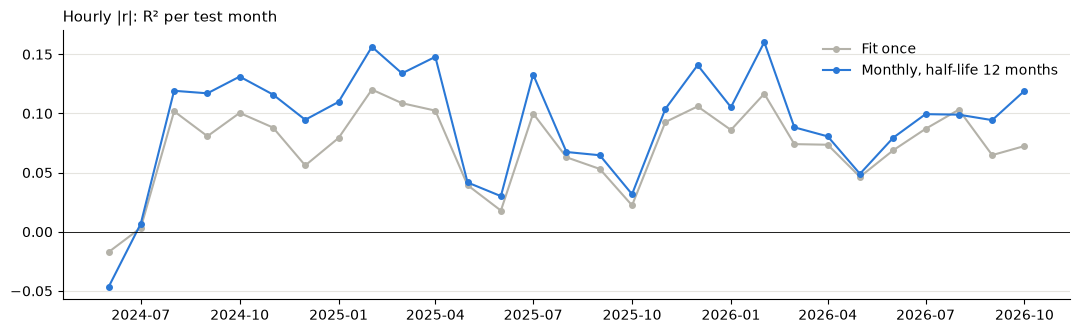

Monthly, half-life 12 months is better in 27 of 29 months


In [20]:
def day_orig(idx):
    # all test origins of the chosen independent days (the last day may be incomplete)
    o = (test_days[idx][:, None] + np.arange(24)).ravel()
    return o[o < len(P["test"])]


days_rows = lambda idx: rows24(day_orig(idx))                        # their 24 long-format rows each
y_te_abs = ya["test"]
once_te, new_te = refit_pred["test", "Fit once"], refit_pred["test", CHOSEN]
gain = lambda i: U.r2(y_te_abs[days_rows(i)], new_te[days_rows(i)]) - U.r2(y_te_abs[days_rows(i)], once_te[days_rows(i)])
b = U.block_bootstrap(gain, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
print(f"R2 gain of '{CHOSEN}' over 'fit once' on test: {gain(np.arange(ND)):+.4f} "
      f"(95% CI {np.percentile(b, 2.5):+.4f} to {np.percentile(b, 97.5):+.4f})")

month = np.repeat(D["test"].to_period("M"), 24)
per_month = pd.DataFrame({v: pd.Series(y_te_abs).groupby(month).apply(lambda s: U.r2(s.values, refit_pred["test", v][s.index]))
                          for v in ["Fit once", CHOSEN]})
fig, ax = plt.subplots(figsize=(13, 3.5))
for (v, col), c in zip(per_month.items(), [GREY, BLUE]):
    ax.plot(col.index.to_timestamp(), col.values, marker="o", ms=4, color=c, label=v)
ax.axhline(0, c="k", lw=0.6)
ax.legend(frameon=False)
tidy(ax, "Hourly |r|: R² per test month")
plt.show()
print(f"{CHOSEN} is better in {(per_month[CHOSEN] > per_month['Fit once']).sum()} of {len(per_month)} months")

SUMMARY.append({"question": "size of each of the next 24 hours (|r|)", "chosen without the test": f"GB, long format, {CHOSEN.lower()}",
                "test result": f"R2 {U.r2(y_te_abs, new_te):.3f} (fit once {U.r2(y_te_abs, once_te):.3f}; ensemble fitted once "
                               f"{abs_tab.loc['Ensemble (Ridge, Extra Trees, GB)', 'R2']:.3f})",
                "simple rule": f"last week x hour profile: R2 {abs_tab.loc['Baseline: last week x hour profile', 'R2']:.3f}"})

**What we see** *(`v3-extensions.ipynb`, section 3)*

- "**Every monthly variant beats 'fit once'**, on validation and on test, and recent data matters more than old data: a 24-month window beats the expanding one, and decaying weights beat a hard window (they keep the old data, but count it less)."
- "**Chosen on validation: half-life 12 months** (val R² 0.1045). On test it reaches **R² 0.148 vs 0.124** for the model fitted once (+19%), with lower MAE. The gain is clearly significant (95% CI +0.018 to +0.029) and holds in **28 of 29 test months**."
- "For comparison: Alberto's whole set of 14 improvements took the test R² from 0.080 to 0.115–0.123. Keeping the model up to date adds about as much again, with the same model and features."

## 7. Hourly prediction ranges

*Section and texts from `bitcoin-models-v3.ipynb`, section 6 (A3), and `v3-extensions.ipynb`, section 4.*

"A single number for an almost unpredictable return will always be ≈ 0. A **range** is far more useful: 'the next hour will move between −0.6% and +0.6% with 80% probability'. It is also honest about uncertainty."

"**Quantile regression** predicts a chosen quantile of the return instead of its mean": q10, q50 (the median) and q90, so [q10, q90] is an **80% prediction interval**. Model: `HistGradientBoostingRegressor(loss="quantile")` on the long format (base + per-hour + B3), with the setting of `v3-extensions.ipynb` (learning rate 0.05, depth 3, leaf 200, 200 trees): "the interval width is not sensitive to them".

**Metrics**
- "**Pinball loss**: the loss that a quantile minimizes. Lower is better."
- "**Coverage**: share of hours inside [q10, q90]. Should be ≈ 80%."
- "**Width**: average q90 − q10. Narrower is better *at the same coverage*."
- "**Coverage by volatility tercile**: coverage on the calmest, middle and wildest third of the hours (by the 'last week × profile' rule). A good interval keeps ≈80% in *all* of them. A fixed interval cannot do that."

**Baselines**: *fixed* (the 10% / 90% quantiles of all train + validation returns) and *volatility-scaled* (the quantiles of r / σ_rule, multiplied by σ_rule of each hour).

**Conformal calibration** *(`v3-extensions.ipynb`)* "corrects the width with errors measured on data the model was not fitted on. [...] the interval is `centre ± f × half-width`, where `f` is the 80% quantile of `|y − centre| / half-width` on the calibration data (`f > 1` widens, `f < 1` narrows)."

| Variant | Model fitted on | Calibration data for f |
|---|---|---|
| Raw | train + validation | none (f = 1) |
| Split conformal | train | the validation block (a fixed f) |
| Rolling conformal, 30 / 90 days | train + validation | the test hours of the last 30 / 90 days whose outcome is already known at the forecast origin (f updated every day) |

,coverage,width %,coverage calm,coverage middle,coverage wild,pinball q10,pinball q90
Baseline: fixed range,0.8759,1.2768,0.9446,0.8835,0.7997,0.0922,0.0911
Baseline: volatility-scaled,0.7883,0.9444,0.7793,0.7809,0.8048,0.0863,0.0845
Gradient Boosting quantile (raw),0.7694,0.8895,0.7606,0.7634,0.7840,0.0833,0.0809
Split conformal (f = 1.032),0.7696,0.8947,0.7523,0.7642,0.7923,0.0839,0.0818
"Rolling conformal, 30 days",0.7991,0.9769,0.7844,0.7935,0.8195,0.0832,0.0810
"Rolling conformal, 90 days",0.8014,0.9754,0.7913,0.7958,0.8171,0.0831,0.0808


MAE skill of the median (q50) against the zero forecast: -0.0008


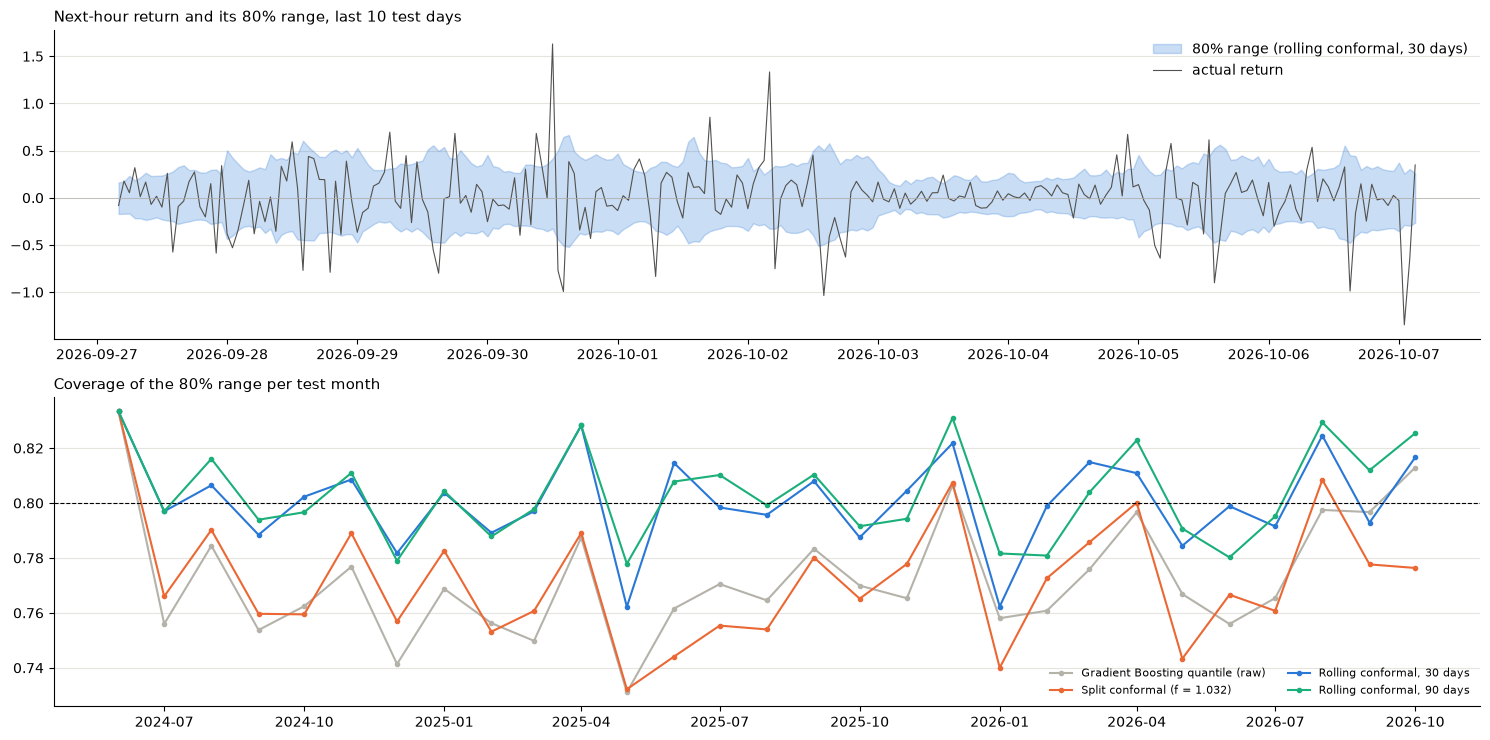

In [21]:
TAUS = (0.1, 0.5, 0.9)
make_q = lambda tau: HistGradientBoostingRegressor(loss="quantile", quantile=tau, early_stopping=False, max_iter=200,
                                                   learning_rate=0.05, max_depth=3, min_samples_leaf=200, random_state=RANDOM_STATE)
q_tv = {t: make_q(t).fit(XR_tv, yr_tv) for t in TAUS}
q_te = np.sort(np.column_stack([q_tv[t].predict(XR["test"]) for t in TAUS]), axis=1)
q_tr = {t: make_q(t).fit(XR["train"], yr["train"]) for t in (0.1, 0.9)}

sigma_tv, sigma_te = np.r_[rule_abs("train"), rule_abs("val")], rule_abs("test")
tercile = pd.qcut(sigma_te, 3, labels=["calm", "middle", "wild"])
y_q = yr["test"]


def interval_row(lo, hi):
    inside = (y_q >= lo) & (y_q <= hi)
    return {"coverage": inside.mean(), "width %": (hi - lo).mean(),
            **{f"coverage {c}": inside[tercile == c].mean() for c in ["calm", "middle", "wild"]},
            "pinball q10": U.pinball(y_q, lo, 0.1), "pinball q90": U.pinball(y_q, hi, 0.9)}


def centre_half(lo, hi):
    return (lo + hi) / 2, (hi - lo) / 2


def f_quantile(y, centre, half):
    s = np.abs(y - centre) / half
    return np.quantile(s, min(1, np.ceil((len(s) + 1) * 0.8) / len(s)))


known_at = (np.repeat(D["test"], 24) + pd.to_timedelta(np.tile(np.arange(1, 25), len(D["test"])), unit="h")).values
test_day = np.repeat(D["test"].normalize(), 24).values


def rolling_f(centre, half, days_back):
    # f for each test day from the hours whose outcome was known at the start of that day
    score, f = np.abs(y_q - centre) / half, np.ones(len(centre))
    order = np.argsort(known_at)
    k_sorted, s_sorted = known_at[order], score[order]
    for d in np.unique(test_day):
        lo_i, hi_i = np.searchsorted(k_sorted, [d - np.timedelta64(days_back, "D"), d], side="right")
        if hi_i - lo_i >= 24 * 24 * 7:                               # at least a week of known outcomes; else f = 1
            f[test_day == d] = np.quantile(s_sorted[lo_i:hi_i], 0.8)
    return f


fixed = np.quantile(yr_tv, [0.1, 0.9])
zq = np.quantile(yr_tv / sigma_tv, [0.1, 0.9])
c_tv, h_tv = centre_half(q_te[:, 0], q_te[:, 2])
lo_tr, hi_tr = np.sort(np.column_stack([q_tr[t].predict(XR["test"]) for t in (0.1, 0.9)]), axis=1).T
lo_va, hi_va = np.sort(np.column_stack([q_tr[t].predict(XR["val"]) for t in (0.1, 0.9)]), axis=1).T
f_split = f_quantile(yr["val"], *centre_half(lo_va, hi_va))
c_tr, h_tr = centre_half(lo_tr, hi_tr)

intervals = {"Baseline: fixed range": (np.full(len(y_q), fixed[0]), np.full(len(y_q), fixed[1])),
             "Baseline: volatility-scaled": (sigma_te * zq[0], sigma_te * zq[1]),
             "Gradient Boosting quantile (raw)": (q_te[:, 0], q_te[:, 2]),
             f"Split conformal (f = {f_split:.3f})": (c_tr - f_split * h_tr, c_tr + f_split * h_tr)}
for days_back in (30, 90):
    f = rolling_f(c_tv, h_tv, days_back)
    intervals[f"Rolling conformal, {days_back} days"] = (c_tv - f * h_tv, c_tv + f * h_tv)
conf_tab = pd.DataFrame({k: interval_row(*v) for k, v in intervals.items()}).T
display(conf_tab.round(4))
print(f"MAE skill of the median (q50) against the zero forecast: {1 - np.abs(y_q - q_te[:, 1]).mean() / np.abs(y_q).mean():+.4f}")

fig, ax = plt.subplots(2, 1, figsize=(15, 7.5))
h1 = np.flatnonzero(np.arange(len(y_q)) % 24 == 0)[-24 * 10:]       # 1-hour-ahead rows of the last 10 days
tt = D["test"][h1 // 24] + pd.Timedelta(hours=1)
lo_r, hi_r = intervals["Rolling conformal, 30 days"]
ax[0].fill_between(tt, lo_r[h1], hi_r[h1], color=BLUE, alpha=0.25, label="80% range (rolling conformal, 30 days)")
ax[0].plot(tt, y_q[h1], lw=0.8, c=INK, label="actual return")
ax[0].axhline(0, c=GREY, lw=0.5)
ax[0].legend(frameon=False)
tidy(ax[0], "Next-hour return and its 80% range, last 10 test days")
month_q = np.repeat(D["test"].to_period("M"), 24)
for (k, (lo, hi)), c in zip([(k, v) for k, v in intervals.items() if not k.startswith("Baseline")], [GREY, ORANGE, BLUE, AQUA]):
    cov = pd.Series((y_q >= lo) & (y_q <= hi)).groupby(month_q).mean()
    ax[1].plot(cov.index.to_timestamp(), cov.values, marker=".", color=c, label=k)
ax[1].axhline(0.8, c="k", ls="--", lw=0.8)
ax[1].legend(frameon=False, fontsize=8, ncol=2)
tidy(ax[1], "Coverage of the 80% range per test month")
plt.tight_layout()
plt.show()

roll30 = conf_tab.loc["Rolling conformal, 30 days"]
SUMMARY.append({"question": "80% range for each of the next 24 hours", "chosen without the test": "GB quantile + rolling conformal (30 days)",
                "test result": f"coverage {roll30['coverage']:.1%} (calm {roll30['coverage calm']:.0%}, wild {roll30['coverage wild']:.0%}), "
                               f"width {roll30['width %']:.2f}%",
                "simple rule": f"fixed range: coverage {conf_tab.loc['Baseline: fixed range', 'coverage']:.1%}, "
                               f"width {conf_tab.loc['Baseline: fixed range', 'width %']:.2f}%"})

**What we see**

*(`bitcoin-models-v3.ipynb`, section 6)*
- "**Pinball loss:** Gradient Boosting has the lowest loss for q10 (0.0834) and q90 (0.0812), better than the volatility-scaled rule (0.0863 / 0.0846) and much better than fixed quantiles (0.0951 / 0.0937)."
- "**Width:** the model's 80% interval is on average **0.89%** wide, against **1.40%** for the fixed one: **36% narrower**."
- "**Conditional coverage** is the clearest result. The fixed interval covers 95.5% of the calm hours (far too wide) but only 82.9% of the wild ones. The model stays at **76–78% in every volatility tercile**, so its width adapts to the market."
- "**Overall coverage is 77%, a little below the 80% target.** The test period behaves slightly differently from the training years, and quantile models trained on past data are known to be slightly over-confident."
- "**The median (q50) has MAE skill ≈ 0** (0.0001): the best 'single number' for the next hour is still ≈ 0%."

**Conclusion of A3:** for hourly returns, the *centre* of the forecast is unpredictable, but the **range** is predictable and can be stated honestly.

*(`v3-extensions.ipynb`, section 4)*
- "**Split conformal does not fix the coverage** (77.0%): on the validation block the raw intervals were almost right (f = 1.03), but the test period behaves differently again. A correction measured once goes out of date, like the model itself in section 3."
- "**Rolling conformal reaches 80.0% (30 days) and 80.2% (90 days)** and keeps 79–82% in calm, middle and wild hours. The price is a 10% wider interval (0.98% instead of 0.89%), still **23% narrower than the fixed range**, which over-covers calm hours (94%) and under-covers wild ones (80%)."
- "**Per month (plot):** the raw and split-conformal intervals stay below 80% in almost every month (73–80%), so the problem is systematic, not bad luck. The rolling versions move around 80% (76–83% per month)."
- *Not rerun here:* "**Monthly refit + rolling conformal** gives the same coverage (80.0%) with the lowest pinball loss of all (q10 0.0823, q90 0.0799): the refitted quantiles are sharper, the calibration keeps them honest."

## 8. Next-day targets: return, direction and volatility

*Section and texts from `bitcoin-models-new-data.ipynb` and `bitcoin-models-2018-2026.ipynb` (section 10), and `bitcoin-models-v3.ipynb` (sections 9, 11, 13, 14).*

"The 24-hour target has three weaknesses: [...] **It is almost pure noise.** [...] **24 outputs are expensive.** [...] **Simple returns are not additive.** +10% then −10% is not 0%. Log returns `ln(1 + r)` fix this: the daily log return is simply the sum of the 24 hourly log returns." *(version 1)*

| Alternative target | Type | Why it can be better |
|---|---|---|
| **A. Next-day log return** = Σ ln(1 + r_h) | regression, 1 value | "Same information as the 24 values for anyone who cares about the day. 24× cheaper to train, simpler to explain. Additive." |
| **B. Next-day direction** (up / down) | classification | "Directly answers the question people ask." |
| **C. Next-day volatility** = log of the realized volatility √Σ(ln(1 + r_h))² | regression, 1 value | "**Volatility is predictable** (calm days follow calm days, wild days follow wild days, the so-called *volatility clustering*). Models show clear, measurable skill, so hyperparameter effects become visible." |

Wide format with the 42 base features. Training uses every 6th origin of train + validation; the test uses the independent days (forecast at 23:00 for the next calendar day).

### 8.1 One validation block or walk-forward folds? (C1, C2)

*(version 3, section 9)* "Version 2 chose hyperparameters on **one** validation block (≈540 days). For the next-day return it picked an extreme setting that then failed on test. Version 1 used walk-forward CV on the training period. Here we combine the two: **4 walk-forward folds over train + validation (Feb 2018 → Jun 2024)**, with a gap of 32 origins (= 192 hours) before each validation fold, and the test block stays untouched." The same Gradient Boosting grid is chosen both ways on targets A and C.

**C2: time-aware early stopping.** "`HistGradientBoostingRegressor(early_stopping=True)` stops adding trees when a score on an internal hold-out stops improving. That hold-out is a **random 10%** of the training rows. With overlapping windows, those rows have near-identical neighbours in the training part, so the hold-out looks easier than real future data and training tends to continue too long. The alternative is to switch early stopping off and treat the number of trees (`max_iter`) as a normal hyperparameter, chosen by walk-forward CV."

In [22]:
XW_tv, XW_te = Ftv, Fte[test_days]
yA_tv, yA_te = U.day_log_return(Ytv), U.day_log_return(Yte[test_days])
yd_tv, yd_te = U.day_log_vol(Ytv), U.day_log_vol(Yte[test_days])
yb_tv, yb_te = (yA_tv > 0).astype(int), (yA_te > 0).astype(int)

GRID_D = {"learning_rate": [0.03, 0.1, 0.3], "max_depth": [1, 2, 4], "min_samples_leaf": [20, 100, 300]}
mk_es = lambda **p: HistGradientBoostingRegressor(early_stopping=True, random_state=RANDOM_STATE, **p)
c1_rows = []
for tname, y_tv_, y_te_, scorer, metric in [("next-day log return", yA_tv, yA_te, r2o, "R2_oos"),
                                          ("next-day log volatility", yd_tv, yd_te, r2s, "R2")]:
    _, p_single = cv_tune(mk_es, GRID_D, XW_tv, y_tv_, SINGLE, scorer, show=False)
    t_wf, p_wf = cv_tune(mk_es, GRID_D, XW_tv, y_tv_, WF, scorer, show=False)
    for how, p in [("single block", p_single), ("walk-forward", p_wf)]:
        pred = mk_es(**p).fit(XW_tv, y_tv_).predict(XW_te)
        wf_row = t_wf.set_index(list(GRID_D)).loc[tuple(p[k] for k in GRID_D)]
        c1_rows.append({"target": tname, "chosen by": how, "params": p, "walk-forward score": wf_row["score"],
                        "walk-forward std": wf_row["score_std"],
                        f"test {metric}": U.r2_oos(y_te_, pred) if metric == "R2_oos" else U.r2(y_te_, pred),
                        "test IC": safe_corr(pred, y_te_)})
display(pd.DataFrame(c1_rows).round(4))

c2_rows = []
base_p = {"learning_rate": 0.1, "max_depth": 2, "min_samples_leaf": 20}
t_es, _ = cv_tune(lambda: HistGradientBoostingRegressor(early_stopping=True, max_iter=2000, random_state=RANDOM_STATE, **base_p),
                  {}, XW_tv, yd_tv, WF, r2s, show=False)
iters = [HistGradientBoostingRegressor(early_stopping=True, max_iter=2000, random_state=RANDOM_STATE, **base_p)
         .fit(XW_tv[a], yd_tv[a]).n_iter_ for a, _ in WF]
t_no, p_no = cv_tune(lambda **p: HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE, **base_p, **p),
                     {"max_iter": [25, 50, 100, 200, 400, 800]}, XW_tv, yd_tv, WF, r2s, show=False)
print("C2, next-day log volatility (learning rate 0.1, depth 2, leaf 20):")
display(t_no[["max_iter", "score", "score_std"]].sort_values("max_iter").set_index("max_iter").T.round(4))
print(f"random early stopping: walk-forward R2 {t_es.loc[0, 'score']:.4f}, trees used per fold {iters}  |  "
      f"tuned max_iter {p_no['max_iter']}: walk-forward R2 {t_no.loc[0, 'score']:.4f}")

,target,chosen by,params,walk-forward score,walk-forward std,test R2_oos,test IC,test R2
0,next-day log return,single block,"{'learning_rate': 0.3, 'max_depth': 2, 'min_sa...",-0.0078,0.0059,-0.0013,0.0468,NaN
1,next-day log return,walk-forward,"{'learning_rate': 0.03, 'max_depth': 1, 'min_s...",0.0022,0.0051,0.0106,0.1400,NaN
2,next-day log volatility,single block,"{'learning_rate': 0.1, 'max_depth': 4, 'min_sa...",0.4487,0.0411,NaN,0.6973,0.4862
3,next-day log volatility,walk-forward,"{'learning_rate': 0.1, 'max_depth': 2, 'min_sa...",0.4511,0.0444,NaN,0.6973,0.4841


C2, next-day log volatility (learning rate 0.1, depth 2, leaf 20):


max_iter,25,50,100,200,400,800
score,0.4142,0.4487,0.4538,0.4516,0.4386,0.4149
score_std,0.0654,0.0521,0.0442,0.0425,0.0406,0.0379


random early stopping: walk-forward R2 0.4462, trees used per fold [92, 228, 160, 336]  |  tuned max_iter 100: walk-forward R2 0.4538


**What we see** *(`bitcoin-models-v3.ipynb`, section 9)*

- "**Next-day return:** the single block picks an extreme setting (learning rate 0.3, depth 1) that is negative on the walk-forward folds (−0.004) and on test (R²_oos −0.002). Walk-forward picks a cautious one (learning rate 0.03, depth 2) that is positive on the folds (+0.003) **and on test (+0.004, IC 0.067)**. This is exactly the failure of version 2, and walk-forward fixes it."
- "**Next-day volatility:** walk-forward again chooses a setting that does better on test (R² 0.478 vs 0.463)."
- "**The fold-to-fold spread is large:** the volatility R² changes by ±0.035–0.043 between periods. Any difference smaller than that, on a single block, cannot be trusted."
- *C2:* "With random early stopping, the hourly model used between 172 and **923** trees depending on the fold: the random hold-out kept saying 'still improving'. Treating the number of trees as a hyperparameter gives a clear optimum: **100 trees** for next-day volatility and **200** for hourly |r|. Beyond that the walk-forward score *decreases*, which is the overfitting that random early stopping does not see."

From here on, every daily model is chosen with the walk-forward folds, and Gradient Boosting has early stopping off and a tuned number of trees.

### 8.2 A. Next-day log return

Metrics as in section 2, now in "% per day" (the MAE is roughly 5× larger than the hourly one). Ridge, Random Forest and Gradient Boosting are chosen by walk-forward R²_oos (`GridSearchCV` with the walk-forward folds refits the best setting on train + validation).

In [23]:
def daily_reg(est, grid, y_tv_, scoring):
    gs = GridSearchCV(est, grid, cv=WF, scoring=scoring, n_jobs=-1).fit(XW_tv, y_tv_)
    return gs, gs.predict(XW_te)


def report_A(pred):
    hits = (pred > 0) == (yA_te > 0)
    return {"MAE": mean_absolute_error(yA_te, pred), "MAE skill": 1 - np.abs(yA_te - pred).mean() / np.abs(yA_te).mean(),
            "R2_oos": U.r2_oos(yA_te, pred), "IC": safe_corr(pred, yA_te), "direction acc": hits.mean(),
            "p-value": stats.binomtest(int(hits.sum()), len(hits), 0.5, alternative="greater").pvalue}


r2oos_scorer = make_scorer(U.r2_oos)
A_rows, A_pred, A_gs = {"Baseline: zero": {"WF R2_oos": 0.0, **report_A(np.zeros_like(yA_te))}}, {}, {}
for name, est, grid in [
    ("Ridge", make_ridge(1.0), {"ridge__alpha": [1, 1e2, 1e3, 1e4, 1e5, 1e6]}),
    ("Random Forest", RandomForestRegressor(n_estimators=200, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE),
     {"max_depth": [1, 2, 3, 6], "min_samples_leaf": [50, 200, 500]}),
    ("Gradient Boosting", HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE),
     {"learning_rate": [0.03, 0.1], "max_depth": [1, 2, 3], "max_iter": [50, 150]}),
]:
    gs, A_pred[name] = daily_reg(est, grid, yA_tv, r2oos_scorer)
    A_gs[name] = gs
    A_rows[f"{name} {gs.best_params_}"] = {"WF R2_oos": gs.best_score_, **report_A(A_pred[name])}
A_tab = pd.DataFrame(A_rows).T
display(A_tab.round(4))
reg_name = max(A_gs, key=lambda k: A_gs[k].best_score_)
SUMMARY.append({"question": "next-day log return", "chosen without the test": f"{reg_name} (best walk-forward R2_oos)",
                "test result": f"R2_oos {U.r2_oos(yA_te, A_pred[reg_name]):+.4f}, IC {safe_corr(A_pred[reg_name], yA_te):+.3f}",
                "simple rule": "zero forecast"})

,WF R2_oos,MAE,MAE skill,R2_oos,IC,direction acc,p-value
Baseline: zero,0.0000,1.6772,0.0000,0.0000,NaN,0.4994,0.5277
Ridge {'ridge__alpha': 10000.0},0.0025,1.6803,-0.0019,0.0013,0.0409,0.5054,0.3906
"Random Forest {'max_depth': 3, 'min_samples_leaf': 50}",0.0005,1.6770,0.0001,0.0064,0.0909,0.4982,0.5552
"Gradient Boosting {'learning_rate': 0.03, 'max_depth': 1, 'max_iter': 50}",-0.0021,1.6755,0.0010,0.0091,0.1530,0.5006,0.5000


**What we see**

*(version 1, section 10.A)* "The first weak but real signal appears. Ridge reaches an IC of 0.094 and R²_oos of +0.009, and Gradient Boosting reaches MAE skill +0.004. Summing 24 noisy hours into one number cancels part of the noise."

*(version 2, conclusion 5)* "Ridge again finds a weak signal: IC 0.063, R²_oos +0.002 [...]. The tree models find nothing. Gradient Boosting chose the most extreme corner of its grid (learning rate 0.3, depth 1, leaf 1000) and then did worse than zero on test (skill −0.008). This shows the main weakness of a *single* validation block."

*(version 3, section 13)* With walk-forward folds Ridge was chosen: "test R²_oos +0.004 and IC 0.058, the best *daily* return numbers of the project."

### 8.3 B. Next-day direction (classification)

| Metric | Meaning | No skill |
|---|---|---|
| **Accuracy** | Share of days with the correct direction | the share of the majority class |
| **Balanced accuracy** | Average of the accuracy on up days and on down days | 0.5 |
| **ROC AUC** | "Probability that the model gives a higher 'up' probability to a random up day than to a random down day" | 0.5 |
| **Log loss** / **Brier score** | How good the predicted probabilities are | log loss ln 2 ≈ 0.693 for always 50/50 |

"Hyperparameters are chosen by ROC AUC, because accuracy can be 'won' by always predicting the majority class." *(version 1)*

Share of up days: train + validation 0.518, test 0.501


,WF AUC,accuracy,p-value,balanced acc,AUC,log loss,Brier
Baseline: always up (train + val up-share),0.5000,0.5006,0.5000,0.5000,0.5000,0.6938,0.2503
Logistic Regression {'logisticregression__C': 1e-05},0.5445,0.5006,0.5000,0.5000,0.5101,0.6937,0.2503
"Random Forest {'max_depth': 1, 'min_samples_leaf': 500}",0.5465,0.5030,0.4448,0.5029,0.5126,0.6944,0.2506
"Gradient Boosting {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 50}",0.5409,0.5223,0.1056,0.5220,0.5052,0.6938,0.2503


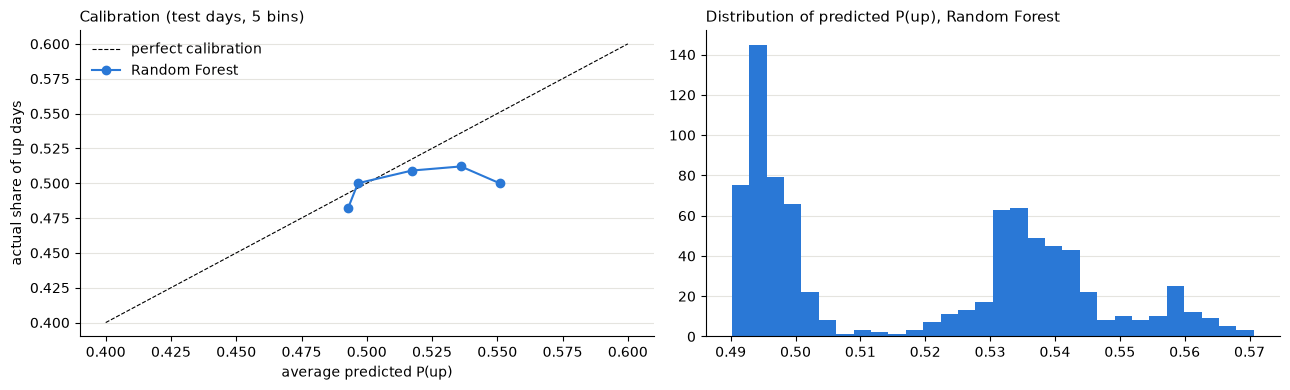

Brier score: Random Forest 0.2506 vs. always the train + val up-share 0.2503 (predicted P(up) ranges 0.490 - 0.571)


In [24]:
def report_B(proba):
    pred = (proba > 0.5).astype(int)
    p = stats.binomtest(int((pred == yb_te).sum()), len(yb_te), 0.5, alternative="greater").pvalue
    return {"accuracy": accuracy_score(yb_te, pred), "p-value": p, "balanced acc": balanced_accuracy_score(yb_te, pred),
            "AUC": roc_auc_score(yb_te, proba) if np.std(proba) > 0 else 0.5,
            "log loss": log_loss(yb_te, np.clip(proba, 1e-6, 1 - 1e-6)), "Brier": np.mean((proba - yb_te) ** 2)}


print(f"Share of up days: train + validation {yb_tv.mean():.3f}, test {yb_te.mean():.3f}")
B_rows = {"Baseline: always up (train + val up-share)": {"WF AUC": 0.5, **report_B(np.full(len(yb_te), yb_tv.mean()))}}
B_proba, B_gs = {}, {}
for name, est, grid in [
    ("Logistic Regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
     {"logisticregression__C": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]}),
    ("Random Forest", RandomForestClassifier(n_estimators=200, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE),
     {"max_depth": [1, 2, 3, 6], "min_samples_leaf": [50, 200, 500]}),
    ("Gradient Boosting", HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
     {"learning_rate": [0.03, 0.1], "max_depth": [1, 2, 3], "max_iter": [50, 150]}),
]:
    gs = GridSearchCV(est, grid, cv=WF, scoring="roc_auc", n_jobs=-1).fit(XW_tv, yb_tv)
    B_gs[name], B_proba[name] = gs, gs.predict_proba(XW_te)[:, 1]
    B_rows[f"{name} {gs.best_params_}"] = {"WF AUC": gs.best_score_, **report_B(B_proba[name])}
display(pd.DataFrame(B_rows).T.round(4))

clf_name = max(B_gs, key=lambda k: B_gs[k].best_score_)
proba_te = B_proba[clf_name]
frac_up, mean_pred = calibration_curve(yb_te, proba_te, n_bins=5, strategy="quantile")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot([0.4, 0.6], [0.4, 0.6], "k--", lw=0.8, label="perfect calibration")
ax[0].plot(mean_pred, frac_up, "o-", color=BLUE, label=clf_name)
ax[0].set_xlabel("average predicted P(up)")
ax[0].set_ylabel("actual share of up days")
ax[0].legend(frameon=False)
tidy(ax[0], "Calibration (test days, 5 bins)")
ax[1].hist(proba_te, bins=30, color=BLUE)
tidy(ax[1], f"Distribution of predicted P(up), {clf_name}")
plt.tight_layout()
plt.show()
print(f"Brier score: {clf_name} {np.mean((proba_te - yb_te) ** 2):.4f} vs. always the train + val up-share "
      f"{np.mean((yb_tv.mean() - yb_te) ** 2):.4f} (predicted P(up) ranges {proba_te.min():.3f} - {proba_te.max():.3f})")
SUMMARY.append({"question": "next-day direction", "chosen without the test": f"{clf_name} (best walk-forward AUC)",
                "test result": f"AUC {roc_auc_score(yb_te, proba_te):.3f}, accuracy {accuracy_score(yb_te, proba_te > 0.5):.1%}",
                "simple rule": f"always up: accuracy {yb_te.mean():.1%}"})

**What we see**

*(version 1, section 10.B)* "ROC AUC 0.52–0.54 against 0.50 for 'always up'. There is a little ranking information, but not enough to change accuracy."

*(version 2, conclusion 5)* "Logistic Regression is the best direction model of the whole notebook: accuracy 52.5%, balanced accuracy 0.523, ROC AUC 0.544, but p = 0.08, so it is still **not significant** at the 5% level. [...] The tree classifiers chose depth 1 and are no better than a coin."

*(version 3, section 14)* "The classifier's probabilities stay between 0.475 and 0.598, and almost all lie in 0.50–0.53: it never makes a confident call. The calibration curve zig-zags around the diagonal [...]. The Brier score (0.2498) is only 0.0004 better than always predicting the training up-share (0.2502). The classifier **'knows that it doesn't know'**: its probabilities are honest, but they carry almost no information."

### 8.4 C. Next-day volatility (C4, C5)

Target: "the log of the next day's realized volatility, `ln √Σ(ln(1 + r_h))²` (in %). The log makes the distribution symmetric, so a calm day and a wild day are treated more evenly." Baselines from volatility research: **yesterday's volatility** and the **average daily volatility of the last week**. "Here the usual R² (against the test mean) is the right metric, because the question is how much of the day-to-day variation in volatility the model explains." *(version 1)*

More models (version 3, C4):

| Model | Idea | Grid |
|---|---|---|
| Ridge | linear | alpha |
| ElasticNet | linear with L1 + L2 penalty (mix of Lasso and Ridge) | alpha, l1_ratio |
| k-Nearest Neighbors | average of the k most similar past days | k |
| SVR (RBF kernel) | non-linear "kernel" regression that ignores errors smaller than `epsilon` | C, gamma |
| Random Forest | averaged deep trees | depth, leaf |
| Extra Trees | random split thresholds: more variety | depth, leaf |
| Gradient Boosting | trees that correct each other | learning rate, depth, leaf, number of trees |

**Ensembles** (C5): "An ensemble averages the forecasts of several models. If their errors are not perfectly correlated, the average is more accurate than each model alone. Two simple versions, with no extra hyperparameters to overfit": the average of the 3 best models (by walk-forward R²) and of all 7. They are scored on the same walk-forward folds.

,best params,WF R2,WF std,fold1,fold2,fold3,fold4
Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 3, 'max_i...",0.458672,0.040604,0.457262,0.515908,0.438167,0.423351
Extra Trees,"{'max_depth': 14, 'min_samples_leaf': 10}",0.454164,0.048111,0.459039,0.515859,0.442072,0.399687
Random Forest,"{'max_depth': 10, 'min_samples_leaf': 10}",0.439644,0.05775,0.459404,0.506812,0.421922,0.370439
SVR,"{'C': 1.0, 'gamma': 0.01}",0.430266,0.030374,0.432452,0.472009,0.403029,0.413573
Ridge,{'alpha': 1.0},0.379987,0.064999,0.41757,0.43167,0.383347,0.287361
ElasticNet,"{'alpha': 0.0003, 'l1_ratio': 0.9}",0.379962,0.065544,0.417654,0.43223,0.383404,0.286562
KNN,{'n_neighbors': 20},0.142095,0.172626,0.103896,-0.071932,0.196359,0.340055
"Ensemble: top 3 (Gradient Boosting, Extra Trees, Random Forest)",-,0.457187,0.04885,0.464728,0.520044,0.440335,0.40364
Ensemble: all 7,-,0.451846,0.042729,0.47228,0.499663,0.432619,0.40282


,WF R2,test R2,test MAE,test corr
Gradient Boosting,0.4587,0.4765,0.2980,0.6926
"Ensemble: top 3 (Gradient Boosting, Extra Trees, Random Forest)",0.4572,0.4848,0.2953,0.6999
Extra Trees,0.4542,0.5001,0.2900,0.7103
Ensemble: all 7,0.4518,0.4626,0.3010,0.6969
Random Forest,0.4396,0.4602,0.3022,0.6815
SVR,0.4303,0.4489,0.3047,0.6782
Ridge,0.3800,0.3470,0.3309,0.6274
ElasticNet,0.3800,0.3460,0.3310,0.6272
KNN,0.1421,0.3245,0.3397,0.6156
Baseline: yesterday's volatility,NaN,-0.1513,0.4411,0.4243


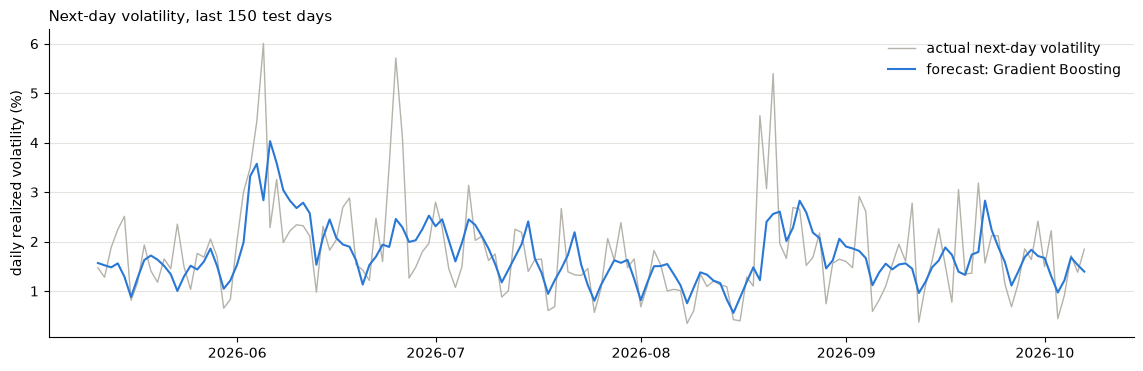

In [25]:
dv_models = {
    "Ridge": (make_ridge, {"alpha": [0.01, 1, 100, 1000]}),
    "ElasticNet": (lambda **p: make_pipeline(StandardScaler(), ElasticNet(max_iter=5000, **p)),
                   {"alpha": [0.0001, 0.0003, 0.003, 0.03], "l1_ratio": [0.01, 0.1, 0.5, 0.9]}),
    "KNN": (lambda **p: make_pipeline(StandardScaler(), KNeighborsRegressor(**p)), {"n_neighbors": [5, 10, 20, 50, 100, 200]}),
    "SVR": (lambda **p: make_pipeline(StandardScaler(), SVR(epsilon=0.1, **p)), {"C": [0.3, 1, 3], "gamma": [0.003, 0.01, 0.03]}),
    "Random Forest": (lambda **p: RandomForestRegressor(n_estimators=200, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE, **p),
                      {"max_depth": [6, 10, 16], "min_samples_leaf": [3, 10, 30]}),
    "Extra Trees": (lambda **p: ExtraTreesRegressor(n_estimators=200, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE, **p),
                    {"max_depth": [8, 14, 20, None], "min_samples_leaf": [3, 10, 30]}),
    "Gradient Boosting": (lambda **p: HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE, **p),
                          {"learning_rate": [0.05, 0.1], "max_depth": [2, 3], "min_samples_leaf": [20, 100], "max_iter": [50, 100, 200]}),
}
dv_best, dv_cv = {}, {}
for name, (mk, grid) in dv_models.items():
    t, dv_best[name] = cv_tune(mk, grid, XW_tv, yd_tv, WF, r2s, show=False)
    dv_cv[name] = t.iloc[0]
dv_summary = pd.DataFrame({k: {"best params": dv_best[k], "WF R2": v["score"], "WF std": v["score_std"],
                               **{f"fold{i}": v[f"fold{i}"] for i in range(1, 5)}} for k, v in dv_cv.items()}).T
dv_summary = dv_summary.sort_values("WF R2", ascending=False)


def wf_predictions(mk, p, X, y, folds):
    return [mk(**p).fit(X[a], y[a]).predict(X[b]) for a, b in folds]


dv_fold_preds = {k: wf_predictions(dv_models[k][0], dv_best[k], XW_tv, yd_tv, WF) for k in dv_models}
fold_y = [yd_tv[b] for _, b in WF]
top3 = list(dv_summary.index[:3])
ens_def = {f"Ensemble: top 3 ({', '.join(top3)})": top3, "Ensemble: all 7": list(dv_models)}
for en, members in ens_def.items():
    sc = [U.r2(fold_y[i], np.mean([dv_fold_preds[m][i] for m in members], axis=0)) for i in range(len(WF))]
    dv_summary.loc[en] = {"best params": "-", "WF R2": np.mean(sc), "WF std": np.std(sc, ddof=1), **{f"fold{i + 1}": s for i, s in enumerate(sc)}}
display(dv_summary)

lr_h = np.log1p(ret / U.PCT) * U.PCT                                 # hourly log returns, %
p_days = P["test"][test_days]
dv_test_pred = {k: dv_models[k][0](**dv_best[k]).fit(XW_tv, yd_tv).predict(XW_te) for k in dv_models}
for en, members in ens_def.items():
    dv_test_pred[en] = np.mean([dv_test_pred[m] for m in members], axis=0)
dv_test_pred["Baseline: yesterday's volatility"] = np.log(np.sqrt(np.array([(lr_h[p - 23: p + 1] ** 2).sum() for p in p_days])) + 1e-6)
NAIVE_DV = "Baseline: last week's average volatility"
dv_test_pred[NAIVE_DV] = np.log(np.sqrt(np.array([(lr_h[p - 167: p + 1] ** 2).sum() / 7 for p in p_days])) + 1e-6)
dv_tab = pd.DataFrame({k: {"WF R2": dv_summary["WF R2"].get(k, np.nan), "test R2": U.r2(yd_te, v),
                           "test MAE": mean_absolute_error(yd_te, v), "test corr": safe_corr(v, yd_te)}
                       for k, v in dv_test_pred.items()}).T
display(dv_tab.sort_values("WF R2", ascending=False).round(4))

dv_name = dv_summary["WF R2"].astype(float).idxmax()                 # chosen on the walk-forward folds
fig, ax = plt.subplots(figsize=(14, 4))
last = slice(-150, None)
ax.plot(D["test"][test_days][last], np.exp(yd_te[last]), color=GREY, lw=1, label="actual next-day volatility")
ax.plot(D["test"][test_days][last], np.exp(dv_test_pred[dv_name][last]), color=BLUE, lw=1.5, label=f"forecast: {dv_name}")
ax.set_ylabel("daily realized volatility (%)")
ax.legend(frameon=False)
tidy(ax, "Next-day volatility, last 150 test days")
plt.show()
SUMMARY.append({"question": "next-day volatility", "chosen without the test": f"{dv_name} (best walk-forward R2)",
                "test result": f"R2 {U.r2(yd_te, dv_test_pred[dv_name]):.3f}",
                "simple rule": f"last week's average: R2 {U.r2(yd_te, dv_test_pred[NAIVE_DV]):.3f}"})

**What we see**

*(versions 1–2, section 10.C)* "**The models clearly work.** [...] Here the non-linear models beat the linear one, and both beat the simple rules by a wide margin." Version 2: Gradient Boosting R² 0.47, Random Forest 0.46, Ridge 0.35, last week's average 0.10, yesterday's volatility −0.16.

*(version 3, section 11)*
- "The non-linear tree models are clearly best for next-day volatility: Gradient Boosting (0.461), Extra Trees (0.456), Random Forest (0.441). SVR is a little lower (0.434) but the **most stable** across folds (std 0.026). Ridge and ElasticNet are equal (0.380): ElasticNet chooses almost no L1 [...], a plateau where it simply *is* Ridge. KNN is very poor and unstable (0.14 ± 0.16). With 55 features, 'similar days' are hard to find (the curse of dimensionality)."
- "For next-day volatility the ensembles do **not** beat the best single model on the walk-forward folds [...]. The three tree models make very similar errors, so averaging them changes little. On the test block, Extra Trees happens to be best (0.496) [...], but these are not choices we could have made without looking at the test, and differences of 0.02–0.03 are smaller than the fold-to-fold spread (±0.04)."
- *(section 12.3)* "the version-2 Gradient Boosting was already close to what these features allow (R² ≈ 0.46–0.50). [...] When the differences between candidates are smaller than the fold-to-fold spread, choosing the 'best' is partly a lottery."

### 8.5 Smarter hyperparameter search (C6)

*(version 3, section 11)* "A full grid tries every combination, so its cost multiplies with every hyperparameter added. Two alternatives from scikit-learn, compared on the next-day volatility Gradient Boosting with a larger search space (3 × 3 × 3 × 3 = 81 combinations), using the same walk-forward folds": `RandomizedSearchCV` (20 random combinations drawn from distributions) against the full `GridSearchCV`. (`HalvingGridSearchCV` is left out: it was faster but slightly worse.)

In [26]:
mk_gb_s = HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE)
space = {"learning_rate": [0.03, 0.1, 0.3], "max_depth": [1, 2, 4], "min_samples_leaf": [10, 50, 300], "max_iter": [50, 150, 400]}
space_rand = {"learning_rate": stats.loguniform(0.01, 0.3), "max_depth": stats.randint(1, 7),
              "min_samples_leaf": stats.randint(5, 400), "max_iter": stats.randint(30, 500)}
c6 = {}
for name, search in [("GridSearchCV (81)", GridSearchCV(mk_gb_s, space, cv=WF, scoring="r2", n_jobs=-1)),
                     ("RandomizedSearchCV (20)", RandomizedSearchCV(mk_gb_s, space_rand, n_iter=20, cv=WF, scoring="r2",
                                                                    n_jobs=-1, random_state=RANDOM_STATE))]:
    t0 = time.time()
    search.fit(XW_tv, yd_tv)
    c6[name] = {"best WF R2": search.best_score_, "settings tried": len(search.cv_results_["params"]),
                "seconds": round(time.time() - t0), "best params": {k: (round(v, 4) if isinstance(v, float) else v)
                                                                     for k, v in search.best_params_.items()},
                "test R2": U.r2(yd_te, search.best_estimator_.predict(XW_te))}
display(pd.DataFrame(c6).T)

,best WF R2,settings tried,seconds,best params,test R2
GridSearchCV (81),0.454812,81,11,"{'learning_rate': 0.03, 'max_depth': 2, 'max_i...",0.483572
RandomizedSearchCV (20),0.455415,20,5,"{'learning_rate': 0.017, 'max_depth': 3, 'max_...",0.482848


**What we see** *(version 3, C6)* "`RandomizedSearchCV` with **20** random settings finds a setting as good as the full grid of **81** (walk-forward R² 0.4574 vs 0.4574), in about a third of the time. [...] **Practical rule:** with more than 2–3 hyperparameters, random search is the better default. It also avoids the 'best value on the grid edge' problem, because it samples from continuous ranges."

### 8.6 Learning curves: does more training data help? (D2)

*(version 3, section 14)* "Each model is trained on the **most recent** 6, 12, 24, 36 months of the train block, or all of it (≈59 months), and scored on the validation block, with fixed hyperparameters. If a target has real, stable structure, the validation score should rise with more data; if it is noise, more data changes nothing." This replaces the "how much history" experiment of versions 1–2 (section 3), which needs data before 2018.

,origins,next-day vol R²,hourly |r| R²,hourly returns R²_oos,hourly returns IC,next-day return IC
months of training,,,,,,
6,733,0.4380,0.0940,-0.0009,-0.0081,-0.0542
12,1461,0.4295,0.1029,-0.0019,0.0062,-0.0047
24,2921,0.4166,0.0943,-0.0003,0.0184,0.0317
36,4385,0.4159,0.0917,0.0005,0.0219,0.0435
59,7149,0.4042,0.0908,0.0005,0.0255,0.0621


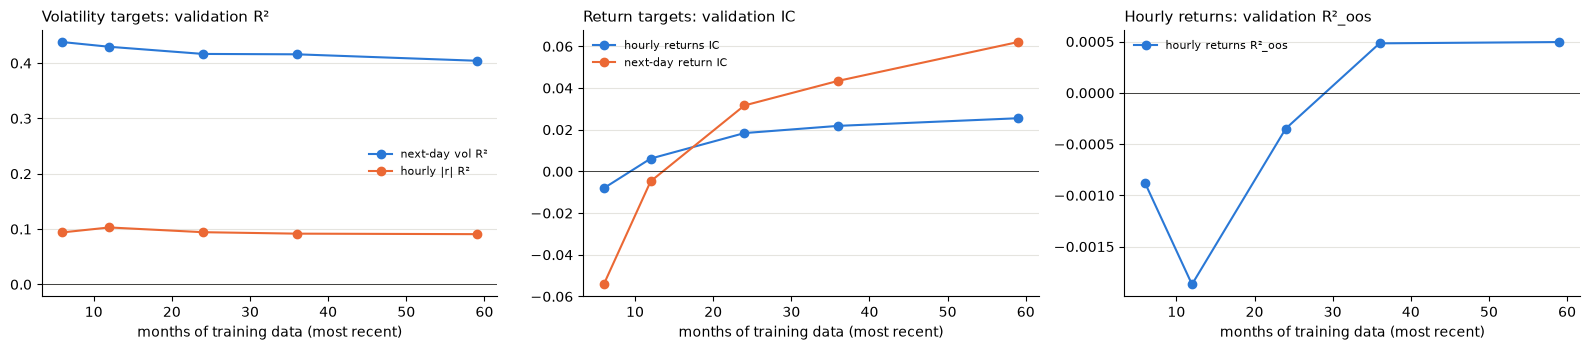

In [27]:
yd_tr, yd_va = U.day_log_vol(Ytr), U.day_log_vol(Yva)
yA_tr, yA_va = U.day_log_return(Ytr), U.day_log_return(Yva)
lc_rows = []
for months in [6, 12, 24, 36, None]:
    sel_o = np.arange(n_tr) if months is None else np.flatnonzero(D["train"] >= D["train"][-1] - pd.DateOffset(months=months))
    sel_r = rows24(sel_o)
    r = {"months of training": months or round((D["train"][-1] - D["train"][0]).days / 30.4), "origins": len(sel_o)}
    gbd = HistGradientBoostingRegressor(learning_rate=0.1, max_depth=2, min_samples_leaf=20, max_iter=100, early_stopping=False,
                                        random_state=RANDOM_STATE)
    r["next-day vol R²"] = U.r2(yd_va, gbd.fit(Ftr[sel_o], yd_tr[sel_o]).predict(Fva))
    r["hourly |r| R²"] = U.r2(ya["val"], make_abs_gb(**p_abs_gb).fit(XA["train"][sel_r], ya["train"][sel_r]).predict(XA["val"]))
    pr = make_ridge(alpha=100_000).fit(XR["train"][sel_r], yr["train"][sel_r]).predict(XR["val"])
    r["hourly returns R²_oos"], r["hourly returns IC"] = U.r2_oos(yr["val"], pr), safe_corr(pr, yr["val"])
    pa = make_ridge(alpha=100_000).fit(Ftr[sel_o], yA_tr[sel_o]).predict(Fva)
    r["next-day return IC"] = safe_corr(pa, yA_va)
    lc_rows.append(r)
lc = pd.DataFrame(lc_rows).set_index("months of training")
display(lc.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for a, cols_, title in [(ax[0], ["next-day vol R²", "hourly |r| R²"], "Volatility targets: validation R²"),
                        (ax[1], ["hourly returns IC", "next-day return IC"], "Return targets: validation IC"),
                        (ax[2], ["hourly returns R²_oos"], "Hourly returns: validation R²_oos")]:
    for col, c in zip(cols_, [BLUE, ORANGE]):
        a.plot(lc.index, lc[col], "o-", color=c, label=col)
    a.axhline(0, c="k", lw=0.5)
    a.set_xlabel("months of training data (most recent)")
    a.legend(frameon=False, fontsize=8)
    tidy(a, title)
plt.tight_layout()
plt.show()

**What we see** *(version 3, D2)*

- "**Volatility targets get *worse* with more history:** next-day volatility R² falls from 0.434 (last 6 months only) to 0.409 (all 59 months), and hourly |r| peaks at 12 months (0.102). The relationship between today's features and tomorrow's volatility **drifts** over time: recent data describes the validation period better than 2018 data does. (Version 2 found the same for the very old years.)"
- "**Return targets need a lot of history:** the hourly return IC rises from −0.004 (6 months) to ≈0.022 (from 24 months on), and the next-day return IC from −0.03 to ≈0.05. The tiny return signal can only be estimated from many examples, and adding more data never makes it large."
- "This suggests two different training strategies: **recent windows (or recency weights) for volatility**, the **full history for returns**." Section 6.5 tested the first one.

## 9. The course-lab pipeline

*Section and texts from `course-methods.ipynb` (Filip), sections 1–4. The Keras MLP (section 6 there) belongs to the neural-network notebook and K-Means (section 5 there) to `data-analysis.ipynb` (section 6.1).*

"This notebook answers both questions using **only the methods from the course labs**, kept as simple as possible. Each forecast is made once a day, at the end of the day (23:00), for the following 24 hours." The targets: `size_next`, the average |hourly change| of the next 24 hours (regression), and `up_next`, 1 if the price is higher after 24 hours (classification).

**Attributes**: "Each attribute describes the last day or the last week, and only uses hours up to the moment of the forecast":

| Attribute | Meaning |
|---|---|
| `ret_1d`, `ret_7d` | price change over the last 24 h and the last 7 days (%) |
| `size_1d` | average size of the hourly changes over the last 24 h (mean \|change\|) |
| `vol_1d`, `vol_7d` | standard deviation of the hourly changes over the last 24 h / 7 days |
| `range_1d` | distance between the highest and the lowest price of the last 24 h (%) |
| `volume_ratio` | traded volume of the last 24 h compared with the weekly average (log) |
| `last_hour` | the change in the last hour |
| `weekday` | the day of the week being predicted (category) |

**Split.** `course-methods.ipynb` trained on 2018–2023 and tested on 2024 onwards. Here the days of train + validation (2018 → Jun 2024) are the training set, with `TimeSeriesSplit` (5 folds) for cross-validation as in the course notebook, and the test days are those of the test block. `size_next` is a level (mean |r| in %), not the log volatility of section 8.4, so their R² values are not directly comparable.

In [28]:
r_h, close, volume = hourly["Return"], hourly["Close"], hourly["Volume"].clip(lower=0)
attributes = pd.DataFrame({
    "ret_1d": (close / close.shift(24) - 1) * 100,
    "ret_7d": (close / close.shift(168) - 1) * 100,
    "size_1d": r_h.abs().rolling(24).mean(),
    "vol_1d": r_h.rolling(24).std(),
    "vol_7d": r_h.rolling(168).std(),
    "range_1d": (hourly["High"].rolling(24).max() / hourly["Low"].rolling(24).min() - 1) * 100,
    "volume_ratio": np.log1p(volume.rolling(24).mean()) - np.log1p(volume.rolling(168).mean()),
    "last_hour": r_h,
    "weekday": (hourly.index + pd.Timedelta(hours=1)).day_name(),
})
attributes["size_next"] = r_h.abs().rolling(24).mean().shift(-24)    # average |hourly change| of the next 24 h
attributes["ret_next"] = (close.shift(-24) / close - 1) * 100         # change over the next 24 h
attributes["up_next"] = (attributes["ret_next"] > 0).astype(int)      # 1 = price higher after 24 h

days = attributes[attributes.index.hour == 23].dropna()               # one forecast per day, at 23:00
fit_days = days[days.index + pd.Timedelta(hours=24) < TEST_START]     # train + validation: the next 24 h end before the test
test_c = days[days.index >= TEST_START - pd.Timedelta(hours=1)]
num_cols = ["ret_1d", "ret_7d", "size_1d", "vol_1d", "vol_7d", "range_1d", "volume_ratio", "last_hour"]
cat_cols = ["weekday"]
X_fit, X_test_c = fit_days[num_cols + cat_cols], test_c[num_cols + cat_cols]
print(f"fit:  {len(fit_days)} days {fit_days.index[0].date()} -> {fit_days.index[-1].date()}")
print(f"test: {len(test_c)} days {test_c.index[0].date()} -> {test_c.index[-1].date()}")
print("Share of up days in the fit days:", round(fit_days["up_next"].mean(), 3))
display(fit_days[num_cols + ["size_next", "ret_next"]].corr()[["size_next", "ret_next"]].drop(["size_next", "ret_next"])
        .sort_values("size_next", ascending=False).round(3))

fit:  2365 days 2018-01-08 -> 2024-06-29
test: 829 days 2024-06-30 -> 2026-10-06
Share of up days in the fit days: 0.51


,size_next,ret_next
size_1d,0.712,0.019
range_1d,0.690,0.032
vol_1d,0.672,0.019
vol_7d,0.660,0.019
volume_ratio,0.190,0.010
last_hour,-0.129,-0.064
ret_1d,-0.133,-0.079
ret_7d,-0.165,0.015


"**Preprocessing pipeline** (as in Lab I, Part XII). A `ColumnTransformer` treats the two kinds of columns differently: numerical attributes: fill missing values with the median (`SimpleImputer`), then standardise (`StandardScaler`); the categorical `weekday`: one-hot encoding (`OneHotEncoder`), 7 columns of 0/1. [...] `make_pipe(model)` puts a fresh copy (`clone`) of it in front of every model, so each model learns its own scaling, and inside the cross-validation the scaler is fitted only on the training part of each fold."

"**Cross-validation for time series.** `cross_val_score` normally mixes the days at random. `TimeSeriesSplit` keeps the order: each fold trains on the past and validates on the following block of days."

### 9.1 How big will the moves be? Regression (Labs II and IV)

"Two simple baselines show whether a model is useful at all: **mean:** always predict the average of the training days (`DummyRegressor`); **same as today:** predict that tomorrow's moves will be as big as today's (`size_1d`)."

fold 1: train 2018-01-08 -> 2019-02-06 | validate 2019-02-07 -> 2020-03-06
fold 2: train 2018-01-08 -> 2020-03-06 | validate 2020-03-07 -> 2021-04-04
fold 3: train 2018-01-08 -> 2021-04-04 | validate 2021-04-05 -> 2022-05-03
fold 4: train 2018-01-08 -> 2022-05-03 | validate 2022-05-04 -> 2023-06-01
fold 5: train 2018-01-08 -> 2023-06-01 | validate 2023-06-02 -> 2024-06-29


,train RMSE,CV RMSE,CV std
model,,,
Mean (baseline),0.3185,0.2957,0.0594
Linear Regression,0.1993,0.1956,0.0517
Decision Tree,0.0000,0.2868,0.0710
Random Forest,0.0743,0.1952,0.0453
Same as today (baseline),NaN,0.2366,NaN


Random Forest grid search, best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 10} | CV RMSE: 0.195
Feature importance: {'num__size_1d': 0.686, 'num__ret_7d': 0.086, 'num__vol_7d': 0.076, 'num__range_1d': 0.045, 'num__ret_1d': 0.024, 'num__vol_1d': 0.023}


SVR best C: 1 | CV RMSE: 0.1982


,RMSE,MAE,R2
Mean (baseline),0.2073,0.1763,-0.6322
Same as today (baseline),0.1624,0.1190,-0.0019
Linear Regression,0.1159,0.0834,0.4900
Random Forest (tuned),0.1211,0.0844,0.4428
SVR,0.1173,0.0823,0.4775


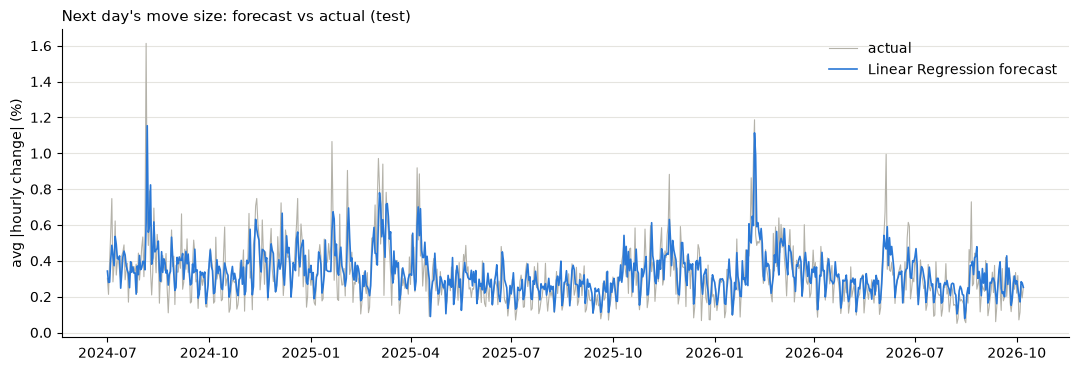

In [29]:
preprocessing = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])


def make_pipe(model):
    # A fresh copy of the preprocessing followed by the model, so models never share fitted steps
    return Pipeline([("prep", clone(preprocessing)), ("model", model)])


cv_c = TimeSeriesSplit(n_splits=5)
for i, (a, b) in enumerate(cv_c.split(X_fit)):
    print(f"fold {i + 1}: train {X_fit.index[a[0]].date()} -> {X_fit.index[a[-1]].date()} | "
          f"validate {X_fit.index[b[0]].date()} -> {X_fit.index[b[-1]].date()}")

y_fit_size, y_test_size = fit_days["size_next"], test_c["size_next"]
regressors = {"Mean (baseline)": DummyRegressor(), "Linear Regression": LinearRegression(),
              "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
              "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)}
rows = []
for name, model in regressors.items():
    pipe = make_pipe(model).fit(X_fit, y_fit_size)
    sc = -cross_val_score(make_pipe(model), X_fit, y_fit_size, cv=cv_c, scoring="neg_root_mean_squared_error")
    rows.append([name, np.sqrt(mean_squared_error(y_fit_size, pipe.predict(X_fit))), sc.mean(), sc.std()])
same_as_today = np.sqrt(np.mean([mean_squared_error(y_fit_size.iloc[b], X_fit["size_1d"].iloc[b]) for _, b in cv_c.split(X_fit)]))
rows.append(["Same as today (baseline)", np.nan, same_as_today, np.nan])
display(pd.DataFrame(rows, columns=["model", "train RMSE", "CV RMSE", "CV std"]).set_index("model").round(4))

grid = GridSearchCV(make_pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
                    {"model__max_depth": [3, 6, 10, None], "model__min_samples_leaf": [1, 10, 30]},
                    cv=cv_c, scoring="neg_root_mean_squared_error").fit(X_fit, y_fit_size)
best_rf_c = grid.best_estimator_
print("Random Forest grid search, best parameters:", grid.best_params_, "| CV RMSE:", round(-grid.best_score_, 4))
importances = pd.Series(best_rf_c["model"].feature_importances_, index=best_rf_c["prep"].get_feature_names_out())
print("Feature importance:", importances.sort_values(ascending=False).round(3).head(6).to_dict())

svr_grid = GridSearchCV(make_pipe(SVR(kernel="rbf", epsilon=0.05)), {"model__C": [0.1, 1, 10]}, cv=cv_c,
                        scoring="neg_root_mean_squared_error").fit(X_fit, y_fit_size)
print("SVR best C:", svr_grid.best_params_["model__C"], "| CV RMSE:", round(-svr_grid.best_score_, 4))

lin_c = make_pipe(LinearRegression()).fit(X_fit, y_fit_size)
size_preds = {"Mean (baseline)": np.full(len(test_c), y_fit_size.mean()), "Same as today (baseline)": X_test_c["size_1d"].values,
              "Linear Regression": lin_c.predict(X_test_c), "Random Forest (tuned)": best_rf_c.predict(X_test_c),
              "SVR": svr_grid.predict(X_test_c)}
size_tab = pd.DataFrame({k: {"RMSE": np.sqrt(mean_squared_error(y_test_size, v)), "MAE": mean_absolute_error(y_test_size, v),
                             "R2": r2_score(y_test_size, v)} for k, v in size_preds.items()}).T
display(size_tab.round(4))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_c.index, y_test_size, lw=0.8, color=GREY, label="actual")
ax.plot(test_c.index, size_preds["Linear Regression"], lw=1.2, color=BLUE, label="Linear Regression forecast")
ax.set_ylabel("avg |hourly change| (%)")
ax.legend(frameon=False)
tidy(ax, "Next day's move size: forecast vs actual (test)")
plt.show()
SUMMARY.append({"question": "next-day move size (course pipeline)", "chosen without the test": "Linear Regression (simplest, CV RMSE close to the best)",
                "test result": f"R2 {size_tab.loc['Linear Regression', 'R2']:.3f} (RF {size_tab.loc['Random Forest (tuned)', 'R2']:.3f}, "
                               f"SVR {size_tab.loc['SVR', 'R2']:.3f})",
                "simple rule": f"same as today: R2 {size_tab.loc['Same as today (baseline)', 'R2']:.3f}"})

**What we see** *(`course-methods.ipynb`, train 2018–2023, test 2024 → Oct 2026)*

- "**Linear Regression (0.199)** and **Random Forest (0.197)** are much better than predicting the mean (0.310), and also better than 'same as today' (0.240). They combine several attributes, e.g. today's moves *and* the weekly volatility, which smooths out one unusual day."
- "**The Decision Tree overfits** exactly as in Lab II: training RMSE 0.000 (it memorised every day), but CV RMSE 0.262, worse than the linear model. The Random Forest averages 200 different trees and overfits much less."
- "**Feature importance:** today's average move size (`size_1d`) dominates (0.51). The weekday is almost irrelevant."
- "**Linear Regression is the best model: R² = 0.48** [...]. The tuned Random Forest is a bit worse (R² 0.41). On this data the simple model generalises better. **Mean (baseline)** has a negative R² (−0.58). The test years were calmer than 2018–2023, so the average of the training days is too high. [...] **'Same as today'** has R² ≈ 0: it gets the level right but overreacts to every single wild day."
- "**SVR** reaches a test R² of **0.46**, almost the same as Linear Regression [...]. The RBF kernel could bend the relationship, but there is little to bend: the move size depends on today's volatility almost linearly."

**Conclusion:** the move size is predictable to a useful degree, mainly because volatility persists from one day to the next.

### 9.2 Which way will the price go? Classification (Labs III and IV)

"The classifiers from Lab III plus a Random Forest, compared with **always predicting the more common class** (`DummyClassifier`)", then the confusion matrix, precision, recall and F1, the ROC curve and a higher decision threshold.

,CV accuracy,CV std,test accuracy,says 'up' on,test AUC
model,,,,,
Majority class (baseline),0.504,0.044,0.501,1.000,0.500
SGD Classifier,0.495,0.038,0.515,0.838,0.500
KNN (k = 50),0.493,0.016,0.487,0.451,0.495
Random Forest,0.536,0.019,0.490,0.485,0.503
SVC (RBF),0.525,0.010,0.514,0.504,0.514


             predicted down  predicted up
actual down             209           205
actual up               218           197

Share of up days in the test set: 0.501   Precision (up): 0.490   Recall (up): 0.475   F1 (up): 0.482
threshold 0.50: says 'up' on  402 days, right on 49.0% of them
threshold 0.55: says 'up' on  160 days, right on 51.9% of them
threshold 0.60: says 'up' on   43 days, right on 48.8% of them


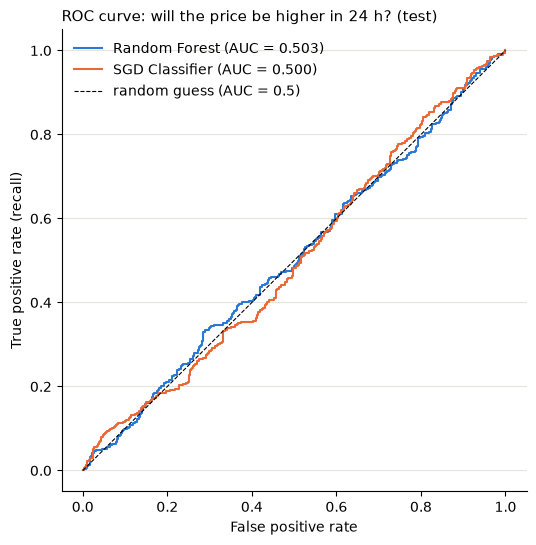

In [30]:
y_fit_up, y_test_up = fit_days["up_next"], test_c["up_next"]
classifiers = {"Majority class (baseline)": DummyClassifier(strategy="most_frequent"), "SGD Classifier": SGDClassifier(random_state=RANDOM_STATE),
               "KNN (k = 50)": KNeighborsClassifier(n_neighbors=50),
               "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=30, random_state=RANDOM_STATE, n_jobs=-1),
               "SVC (RBF)": SVC(kernel="rbf", C=1)}
rows, fitted_c = [], {}
for name, model in classifiers.items():
    cv_acc = cross_val_score(make_pipe(model), X_fit, y_fit_up, cv=cv_c, scoring="accuracy")
    fitted_c[name] = make_pipe(model).fit(X_fit, y_fit_up)
    pred = fitted_c[name].predict(X_test_c)
    score = fitted_c[name].decision_function(X_test_c) if hasattr(fitted_c[name], "decision_function") else fitted_c[name].predict_proba(X_test_c)[:, 1]
    rows.append([name, cv_acc.mean(), cv_acc.std(), accuracy_score(y_test_up, pred), pred.mean(),
                 roc_auc_score(y_test_up, score) if np.std(score) > 0 else 0.5])
cls_tab = pd.DataFrame(rows, columns=["model", "CV accuracy", "CV std", "test accuracy", "says 'up' on", "test AUC"]).set_index("model")
display(cls_tab.round(3))

rf_clf = fitted_c["Random Forest"]
pred_up = rf_clf.predict(X_test_c)
proba_up = rf_clf.predict_proba(X_test_c)[:, 1]
print(pd.DataFrame(confusion_matrix(y_test_up, pred_up), index=["actual down", "actual up"], columns=["predicted down", "predicted up"]))
print(f"\nShare of up days in the test set: {y_test_up.mean():.3f}   Precision (up): {precision_score(y_test_up, pred_up):.3f}   "
      f"Recall (up): {recall_score(y_test_up, pred_up):.3f}   F1 (up): {f1_score(y_test_up, pred_up):.3f}")
for threshold in [0.5, 0.55, 0.6]:
    chosen = proba_up >= threshold
    if chosen.sum() > 0:
        print(f"threshold {threshold:.2f}: says 'up' on {chosen.sum():4d} days, right on {y_test_up[chosen].mean():.1%} of them")

fig, ax = plt.subplots(figsize=(6, 6))
for (name, score), c in zip([("Random Forest", proba_up), ("SGD Classifier", fitted_c["SGD Classifier"].decision_function(X_test_c))], [BLUE, ORANGE]):
    fpr, tpr, _ = roc_curve(y_test_up, score)
    ax.plot(fpr, tpr, color=c, label=f"{name} (AUC = {roc_auc_score(y_test_up, score):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="random guess (AUC = 0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(frameon=False)
tidy(ax, "ROC curve: will the price be higher in 24 h? (test)")
plt.show()
best_c = cls_tab.drop("Majority class (baseline)")["CV accuracy"].idxmax()
SUMMARY.append({"question": "next-day direction (course pipeline)", "chosen without the test": f"{best_c} (best CV accuracy)",
                "test result": f"accuracy {cls_tab.loc[best_c, 'test accuracy']:.1%}, AUC {cls_tab.loc[best_c, 'test AUC']:.3f}",
                "simple rule": f"majority class: accuracy {cls_tab.loc['Majority class (baseline)', 'test accuracy']:.1%}"})

**What we see** *(`course-methods.ipynb`)*

- "**Accuracy:** no classifier beats the coin flip on the test set. The majority class gets 50.6 %, and the models 49.0–51.3 %."
- "**Cross-validation:** the Random Forest's 53.5 % CV accuracy did not hold up on new data (51.3 % on the test set)."
- "**Confusion matrix:** the Random Forest makes almost as many mistakes as hits in both classes [...]. Precision, recall and F1 are all ≈ 0.52."
- "**ROC-AUC:** 0.503 (Random Forest) and 0.496 (SGD). Both curves lie on the diagonal of random guessing, so the models cannot even *rank* up days above down days."
- "**Threshold:** a higher threshold makes the model more selective. At 0.60 it says 'up' on only 50 days and is right on 30 of them (60 %). With only 50 days this can easily be luck: the chance of ≥ 30 hits out of 50 by pure guessing is about 12 %. Precision does not rise steadily with the threshold either [...], which a real signal would show."
- *SVC:* "51.2 % accuracy and an AUC of 0.511, again a coin flip. It says 'up' on 56 % of the days, i.e. it mostly learned that up days are slightly more common."

"**Conclusion:** with daily data and these attributes, the direction of the next day is **not predictable**. This agrees with version 3 of the project and with the idea of an efficient market: if the direction were easy to predict, traders would already have used it."

## 10. What are the forecasts worth? An economic test

*Section and texts from `bitcoin-models-v3.ipynb`, section 13 (D3).*

"R² and accuracy say how close the forecasts are; a trading test says whether that matters. Every strategy decides its position at the forecast origin [here 23:00 UTC] for the next 24 hours, on the [...] independent test days, and pays a **cost of 0.1% per unit of position changed** (a typical exchange fee)."

| Strategy | Position for the next day | Uses |
|---|---|---|
| Buy & hold | always 1 (fully invested) | nothing |
| **Volatility targeting, naive** | σ* / σ̂, capped at 2, with σ̂ = last week's daily volatility | the simple volatility rule |
| **Volatility targeting, model** | the same, with σ̂ from the next-day volatility model chosen in section 8.4 | the volatility forecast |
| Direction, classifier | 1 if P(up) > 0.5, else 0 | the classifier chosen in section 8.3 |
| Direction, return model | 1 if the forecast next-day return > 0, else 0 | the return model chosen in section 8.2 |

"**Volatility targeting** is a standard risk-management rule: hold less when the market is expected to be wild, more when it is expected to be calm, so the risk stays roughly constant. σ* is the median daily volatility of train + validation [...]. It does not try to predict the direction at all. If the volatility forecast is good, the strategy should have a **better return per unit of risk (Sharpe ratio)** and **smaller drawdowns** than buy & hold."

,annual return,annual vol,Sharpe,max drawdown,final value of 1,avg position,turnover per day,Sharpe before costs
Buy & hold,0.228,0.456,0.501,0.531,1.327,1.000,0.000,0.502
"Vol targeting, naive",0.185,0.516,0.358,0.627,1.125,1.224,0.066,0.405
"Vol targeting, model",0.125,0.549,0.228,0.670,0.945,1.374,0.194,0.358
Direction: Random Forest,0.046,0.367,0.127,0.551,0.954,0.583,0.470,0.593
Direction: Ridge return model,-0.003,0.358,-0.008,0.573,0.860,0.636,0.366,0.366


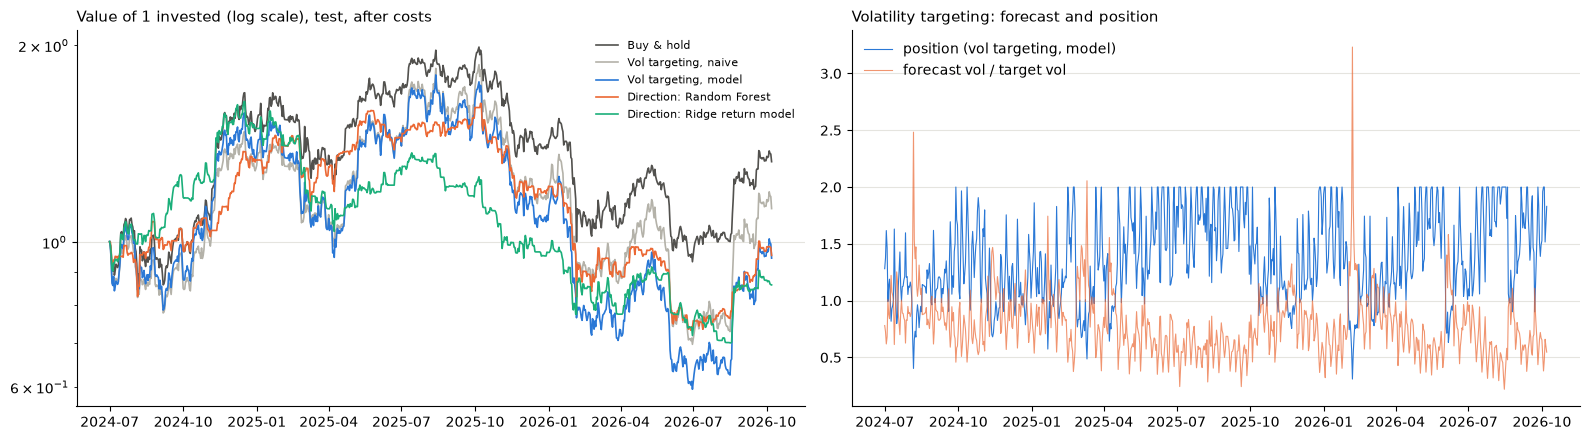

In [31]:
day_ret = U.compound(Yte[test_days]) / 100                           # realized next-day simple return
vol_model = np.exp(dv_test_pred[dv_name])                            # forecast daily volatility, %
vol_naive = np.exp(dv_test_pred[NAIVE_DV])
sigma_star = np.median(np.exp(yd_tv))
positions = {"Buy & hold": np.ones(len(day_ret)),
             "Vol targeting, naive": np.minimum(sigma_star / vol_naive, 2),
             "Vol targeting, model": np.minimum(sigma_star / vol_model, 2),
             f"Direction: {clf_name}": (proba_te > 0.5).astype(float),
             f"Direction: {reg_name} return model": (A_pred[reg_name] > 0).astype(float)}


def backtest(pos, r=day_ret, cost=COST):
    return pos * r - cost * np.abs(np.diff(np.r_[0, pos]))


def perf(sr, pos):
    eq = np.cumprod(1 + sr)
    dd = 1 - eq / np.maximum.accumulate(eq)
    gross = pos * day_ret
    return {"annual return": sr.mean() * 365, "annual vol": sr.std() * np.sqrt(365), "Sharpe": sr.mean() / sr.std() * np.sqrt(365),
            "max drawdown": dd.max(), "final value of 1": eq[-1], "avg position": pos.mean(),
            "turnover per day": np.abs(np.diff(pos)).mean(), "Sharpe before costs": gross.mean() / gross.std() * np.sqrt(365)}


strat = {k: backtest(p) for k, p in positions.items()}
perf_tab = pd.DataFrame({k: perf(strat[k], positions[k]) for k in positions}).T
display(perf_tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for (k, s), c in zip(strat.items(), [INK, GREY, BLUE, ORANGE, AQUA]):
    ax[0].plot(D["test"][test_days], np.cumprod(1 + s), color=c, lw=1.2, label=k)
ax[0].set_yscale("log")
ax[0].legend(frameon=False, fontsize=8)
tidy(ax[0], "Value of 1 invested (log scale), test, after costs")
ax[1].plot(D["test"][test_days], positions["Vol targeting, model"], lw=0.8, color=BLUE, label="position (vol targeting, model)")
ax[1].plot(D["test"][test_days], vol_model / sigma_star, lw=0.8, color=ORANGE, alpha=0.7, label="forecast vol / target vol")
ax[1].legend(frameon=False)
tidy(ax[1], "Volatility targeting: forecast and position")
plt.tight_layout()
plt.show()
SUMMARY.append({"question": "volatility targeting (economic test)", "chosen without the test": f"position = target / forecast ({dv_name}), cap 2",
                "test result": f"Sharpe {perf_tab.loc['Vol targeting, model', 'Sharpe']:.2f}, max drawdown {perf_tab.loc['Vol targeting, model', 'max drawdown']:.0%}",
                "simple rule": f"buy & hold: Sharpe {perf_tab.loc['Buy & hold', 'Sharpe']:.2f}, max drawdown {perf_tab.loc['Buy & hold', 'max drawdown']:.0%}"})

**What we see** *(`bitcoin-models-v3.ipynb`, section 13)*

- "**Direction models.** [...] The classifier's 'long or flat' strategy ends slightly ahead of buy & hold (Sharpe 0.60 vs 0.57, same drawdown), but its AUC is not significantly above 0.5 (section 14), so this is not distinguishable from luck. The return model's strategy **loses** (Sharpe −0.01): it is out of the market on many strong days and trades a lot (turnover 0.35/day). A positive IC on log returns does not automatically make money."
- "**Volatility targeting does worse than buy & hold** (Sharpe 0.29 model, 0.44 naive, vs 0.57). Two reasons [...]:
  1. **The target was set on train + validation, which were more volatile than the test period.** The forecast volatility was usually below the target, so the strategy held **1.4× leverage on average** and often hit the cap of 2. It amplified the 2026 drawdowns (max drawdown 66% vs 53%).
  2. **Costs:** the model's forecast changes every day, so the position changes a lot (turnover 0.195/day ≈ 7% of capital per year in fees). Even *before* costs its Sharpe (0.42) is below buy & hold."

"**Conclusion of D3:** a good volatility forecast (R² ≈ 0.47) is **not** automatically a profitable strategy. The design choices (target level, leverage cap, how often to rebalance) matter as much as the forecast. They were *not* tuned here: tuning them on the test period would be cheating."

## 11. How sure are we? Bootstrap confidence intervals

*Section and texts from `bitcoin-models-v3.ipynb`, section 14 (D1).*

"Every test number so far is a single value from one 2.25-year period. The **moving-block bootstrap** estimates how much it could change with a different sample of days: the [...] test days are resampled in blocks of 10 consecutive days (blocks keep the volatility clustering intact) 1,000 times, and the statistic is recomputed each time. The 2.5% and 97.5% percentiles give a 95% confidence interval. For a **difference** between two models (computed on the same resampled days), an interval that excludes 0 means the difference is reliable."

For the hourly targets a resampled day brings all 24 test origins of that day.

In [32]:
abs_ens, rule_te = abs_test_pred["Ensemble (Ridge, Extra Trees, GB)"], abs_test_pred["Baseline: last week x hour profile"]
gb_r2 = ret_pred_te[[k for k in ret_pred_te if k.startswith("Gradient Boosting") and "R2_oos" in k][0]]
naive_dv = dv_test_pred[NAIVE_DV]
sharpe = lambda s: s.mean() / s.std() * np.sqrt(365)
boot_stats = {
    f"next-day vol R², {dv_name}": lambda i: U.r2(yd_te[i], dv_test_pred[dv_name][i]),
    f"next-day vol R², {dv_name} − last week's average": lambda i: U.r2(yd_te[i], dv_test_pred[dv_name][i]) - U.r2(yd_te[i], naive_dv[i]),
    "hourly |r| R², ensemble": lambda i: U.r2(ya["test"][days_rows(i)], abs_ens[days_rows(i)]),
    "hourly |r| R², ensemble − rule": lambda i: U.r2(ya["test"][days_rows(i)], abs_ens[days_rows(i)]) - U.r2(ya["test"][days_rows(i)], rule_te[days_rows(i)]),
    f"hourly |r| R², {CHOSEN.lower()} − fit once": gain,
    "hourly returns IC, GB chosen by R²_oos": lambda i: safe_corr(gb_r2[days_rows(i)], yr["test"][days_rows(i)]),
    "hourly returns R²_oos, GB chosen by R²_oos": lambda i: U.r2_oos(yr["test"][days_rows(i)], gb_r2[days_rows(i)]),
    "next-hour direction AUC − 0.5, reversal rule": lambda i: roc_auc_score(y1["test"][day_orig(i)] > 0, dir_scores["Reversal rule"][day_orig(i)]) - 0.5,
    f"next-day direction AUC − 0.5, {clf_name}": lambda i: roc_auc_score(yb_te[i], proba_te[i]) - 0.5,
    "Sharpe, vol targeting (model) − buy & hold": lambda i: sharpe(strat["Vol targeting, model"][i]) - sharpe(strat["Buy & hold"][i]),
}
boot_rows = {}
for name, fn in boot_stats.items():
    b = U.block_bootstrap(fn, ND, n_boot=1000, block=10, seed=RANDOM_STATE)
    boot_rows[name] = {"estimate": fn(np.arange(ND)), "CI 2.5%": np.percentile(b, 2.5), "CI 97.5%": np.percentile(b, 97.5),
                       "share of resamples > 0": (b > 0).mean()}
display(pd.DataFrame(boot_rows).T.round(4))

,estimate,CI 2.5%,CI 97.5%,share of resamples > 0
"next-day vol R², Gradient Boosting",0.4765,0.4159,0.5292,1.000
"next-day vol R², Gradient Boosting − last week's average",0.3824,0.3218,0.4461,1.000
"hourly |r| R², ensemble",0.1153,0.0953,0.1385,1.000
"hourly |r| R², ensemble − rule",0.0624,0.0494,0.0757,1.000
"hourly |r| R², monthly, half-life 12 months − fit once",0.0218,0.0166,0.0279,1.000
"hourly returns IC, GB chosen by R²_oos",0.0175,-0.0013,0.0343,0.968
"hourly returns R²_oos, GB chosen by R²_oos",0.0003,-0.0004,0.0010,0.828
"next-hour direction AUC − 0.5, reversal rule",0.0279,0.0206,0.0351,1.000
"next-day direction AUC − 0.5, Random Forest",0.0126,-0.0218,0.0495,0.776
"Sharpe, vol targeting (model) − buy & hold",-0.2723,-0.6098,0.0921,0.077


**What the intervals say** *(`bitcoin-models-v3.ipynb`, section 14, test Jul 2024 → Oct 2026)*

| Result | 95% interval | Verdict |
|---|---|---|
| next-day volatility R² | 0.40 – 0.52 | clearly predictable |
| hourly \|r\| R² | 0.10 – 0.14 | clearly predictable |
| hourly \|r\|: model − best rule | **+0.054 – +0.082** | the model is reliably better than the rule |
| hourly returns IC | −0.008 – +0.032 | includes 0: no reliable signal |
| hourly returns R²_oos | −0.0011 – +0.0011 | centred on 0 |
| next-day direction AUC − 0.5 | −0.013 – +0.062 | includes 0: not reliably better than a coin |
| Sharpe: vol targeting (model) − buy & hold | −0.64 – +0.06 | worse, at the edge of significance |

"The intervals separate the project's results into two groups. **Volatility (daily and hourly) is predictable with high confidence. Returns and direction are not distinguishable from zero.** That is the central result." `v3-extensions.ipynb` adds two rows to the first group: the gain of the monthly refit (+0.018 to +0.029) and the next-hour reversal (p < 10⁻⁴ on the confident calls).

## 12. Conclusions

### 12.1 This run

The main test result of each section, every model chosen without looking at the test block:

In [33]:
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(SUMMARY).set_index("question"))
print(f"Total run time: {(time.time() - T_START) / 60:.1f} minutes")

,chosen without the test,test result,simple rule
question,,,
"24 hourly returns (wide, v1-v2)",best of 5 tuned models,MAE skill -0.0005 to -0.0002,zero forecast: 0 by definition
"24 hourly returns (long, v3)","Ridge / GB by MAE, R2_oos or IC; ElasticNet","IC 0.004 to 0.018, best DM p (sq) 0.16",zero forecast
direction of the next hour,"GB classifier, base + Binance","AUC 0.540, top 10% right 56.6% (p = 3e-09)",reversal rule: AUC 0.528
size of each of the next 24 hours (|r|),"GB, long format, monthly, half-life 12 months",R2 0.144 (fit once 0.122; ensemble fitted once 0.115),last week x hour profile: R2 0.053
80% range for each of the next 24 hours,GB quantile + rolling conformal (30 days),"coverage 79.9% (calm 78%, wild 82%), width 0.98%","fixed range: coverage 87.6%, width 1.28%"
next-day log return,Ridge (best walk-forward R2_oos),"R2_oos +0.0013, IC +0.041",zero forecast
next-day direction,Random Forest (best walk-forward AUC),"AUC 0.513, accuracy 50.3%",always up: accuracy 50.1%
next-day volatility,Gradient Boosting (best walk-forward R2),R2 0.477,last week's average: R2 0.094
next-day move size (course pipeline),"Linear Regression (simplest, CV RMSE close to the best)","R2 0.490 (RF 0.443, SVR 0.478)",same as today: R2 -0.002


Total run time: 27.1 minutes


### 12.2 The assigned task: the 24 hourly returns

1. **Hourly changes cannot be predicted better than "no change".** Every tuned model of section 3 ends up within 0.0001 percentage points of the zero forecast's MAE (0.3193%), and the long-format models of section 4 have R²_oos within ±0.001 of zero (Diebold–Mariano p ≥ 0.16). This matches the well-known behaviour of short-term prices, which are close to a random walk, so it is a correct result rather than a failure of the models.
2. **Beware of direction accuracy.** On this balanced test block (50.1% up days) the models that say "always up" get 50.1% and the best model 51.0% (p = 0.29). On a test period with more up days, "always up" would look like skill; balanced accuracy and the binomial test on independent days guard against that.
3. **Hyperparameters behave as theory predicts.** For every model, the more freedom it gets, the worse it does on new data (section 3): the signature of a target that is mostly noise.
4. **What is left is tiny and short-lived.** The only usable direction information is the reversal of the last hour, for the next hour only (section 5; MAE skill > 0 only at hour 1 in section 3). Two things hide even that in the version-2 setup: the **metric mismatch** (models trained for the mean but chosen by MAE, which rewards predicting 0: IC 0.004 → 0.018 with the matching criterion, section 4) and a **target that ignores the predictable part**, the *size* of the hourly moves (section 6).

### 12.3 Ask the questions the data can answer

*(`bitcoin-models-v3.ipynb`, conclusion 2, and `v3-extensions.ipynb`, conclusions)*

| 24-hour task, reformulated | Best result on test (archived runs) | vs. simple rule | Reliable? |
|---|---|---|---|
| **Size of each of the 24 next hours** (A2 + A6) | R² 0.115–0.123 fitted once; **0.148 refitted every month** (12-month half-life) | rule 0.053 | yes: model − rule = +0.054 to +0.082; refit gain +0.018 to +0.029 |
| **80% range for each of the 24 next hours** (A3) | 36% narrower than fixed ranges; with rolling conformal **80.0% coverage**, 79–82% in calm and wild hours, still 23% narrower | fixed range: 95% / 83% in calm / wild hours | yes |
| **Direction / size of each hour** (A4 + all) | IC 0.010–0.020, R²_oos ≈ 0 | zero forecast | no: IC interval includes 0, DM p ≥ 0.13 |
| **Direction of the next hour only** | AUC 0.537; 55% right on the 10% most confident calls | reversal rule AUC 0.528 | yes (p < 10⁻⁴), but small and before costs |
| **Next-day volatility** | R² 0.46–0.50 | last week's average 0.10 | yes: 0.40 – 0.52 |
| **Next-day move size** (course pipeline) | Linear Regression R² 0.48, SVR 0.46, Random Forest 0.41 | same as today ≈ 0 | — |
| **Next-day return / direction** | IC ≈ 0.06–0.09; AUC 0.52–0.54 | zero / always up | no |

The assigned 24-hour structure is kept, but the forecast becomes "how much will each hour move, and within which range", which is useful (risk, position sizing, execution timing), where the forecast "≈ 0% every hour" is not.

### 12.4 What each experiment did

| Experiment | Effect |
|---|---|
| **A6** long format | "**largest single gain** [of version 3]: hourly volatility R² +43% on validation; leave-one-out confirms it is the key ingredient for both hourly targets" |
| **A2 / A3** new hourly targets | "turn the 24-hour task into one with clear, significant skill" |
| **A4** matching metric | "return IC 0.005 → 0.020 and R²_oos turns positive; not significant" |
| **B1 / B2** 30-day and range-based volatility | "no gain (the base features already contain the information)" |
| **B3** per-hour features | "almost doubles the walk-forward return IC (0.013 → 0.024); neutral for volatility" |
| Binance order flow / ETH | no gain for the size of the hourly moves nor for the next-hour direction (`v3-extensions.ipynb`) |
| **C1** walk-forward CV | "fixes the bad next-day-return choice of version 2 and shows the true uncertainty (±0.04 R² between periods)" |
| **C2** tuned number of trees | "small, consistent gain; random early stopping used up to 4–5× too many trees" |
| **A5 / C3** scaled target, weights, Huber | "helps linear return models on validation only; nothing robust on test" (not rerun) |
| **C4** more models | "trees > SVR > linear > KNN for volatility; ElasticNet keeps 5 return features". On daily attributes, plain Linear Regression beats the Random Forest (`course-methods.ipynb`) |
| **C5** ensembles | "+7% for hourly volatility (walk-forward); no gain for next-day volatility" |
| **C6** random search | "same result as the full grid at 1/3 of the cost" |
| Monthly refit with recency weights | the largest single improvement of the project: hourly \|r\| R² 0.124 → 0.148, better in 28 of 29 months (`v3-extensions.ipynb`) |
| Rolling conformal calibration | 80% ranges that really cover 80% (`v3-extensions.ipynb`) |

### 12.5 The broader lessons

*(`bitcoin-models-v3.ipynb`, conclusion 4, and `v3-extensions.ipynb`)*

- "**More tuning does not beat noise.** For returns, every improvement helped on validation and none survived to the test block in a significant way. For next-day volatility, the 'improved' pipeline was slightly worse on test. When the differences between candidates are smaller than the fold-to-fold spread, model selection itself is partly random. Confidence intervals [...] are the only honest way to report such results."
- "**A good forecast is not automatically a good strategy.** Volatility targeting with an R² ≈ 0.47 forecast still lost to buy & hold, because of its design (target level, leverage, trading costs), not because of the forecast."
- "**Volatility relationships drift; return signals are tiny.** Volatility models do better with recent data, return models need all the history they can get."
- "Bitcoin's behaviour drifts (e.g. the new 14 UTC volatility peak since the ETFs), so **keeping models and calibrations up to date matters more than extra data sources**."
- *(`course-methods.ipynb`)* "More complex models did not help, because the relationship is close to linear and there are only about 2,000 training days."

### 12.6 Limitations

*(`bitcoin-models-v3.ipynb`, conclusion 5)*

- "**One test period** (2.25 years). A different period could rank the close variants differently, as the bootstrap intervals show."
- "**Many tests on the return target** [...]. The few p-values below 0.05 for confident forecasts [...] are what multiple testing produces by chance; none was the validation choice."
- "**A few best hyperparameters still lie on a grid edge** [...]. In every case the neighbouring value scores within the selection noise (a plateau)."
- "The economic test ignores slippage, funding costs of leverage and taxes."
- The base data starts in 2018, so the "how much history" experiment of versions 1–2 (training from 2012) cannot be repeated on it.

### 12.7 Not rerun here

- **Neural networks** (`MLPRegressor`, Keras MLP, RNN/LSTM): the separate neural-network notebook.
- Version 3: the volatility-scaled target, sample weights and Huber loss (A5, C3), permutation importance (B4), `HalvingGridSearchCV`, the walk-forward evaluation of the hourly \|r\| ensemble (C5), the leave-one-out ablation of all improvements together (section 12), regimes (D4; the regimes themselves are in `data-analysis.ipynb`, section 6.2) and the linear quantile regression.
- `v3-extensions.ipynb`: the monthly refit of the quantile models with rolling conformal calibration; the 12-month window and 24-month half-life variants.

### 12.8 Recommended story

*(`bitcoin-models-v3.ipynb`)* "Hourly Bitcoin returns are close to a random walk: their direction carries less than 1% predictable variance, and no amount of model tuning makes it reliably predictable. Asking the questions the data *can* answer changes everything: one scikit-learn model in long format predicts the size of each of the next 24 hours 2.2× better than a volatility rule, and quantile models give 80% ranges that are 36% narrower than fixed ones and adapt to calm and wild markets. Walk-forward validation, bootstrap intervals and an economic test keep the conclusions honest: volatility is predictable, direction is not, and a good forecast still needs a good decision rule to be useful."

*(`v3-extensions.ipynb`)* "**For the 24-hour task:** the best forecast this project has for 'how much will each of the next 24 hours grow or shrink' is
- the **size** of each hour from Gradient Boosting in long format, **refitted every month with a 12-month half-life** (R² ≈ 0.15),
- an **80% range** for each hour from the quantile models with **rolling conformal calibration** (honest 80% coverage),
- and a **direction** only for the next hour (reversal of the last hour, ≈ 55% on confident calls); for hours 2–24 the direction stays a coin flip."